In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import LambdaCDM
from matplotlib.lines import Line2D
from scipy.stats import chi2
import emcee
import corner
from pathlib import Path

In [25]:
def read_snana_file(filename):
    with open(filename, "r") as file:
        lines = file.readlines()

    header_line = next(line for line in lines if line.startswith("VARNAMES:"))

    columns = header_line.split()[1:]

    data_rows = [line.split()[1:] for line in lines if line.startswith("SN:")]

    df = pd.DataFrame(data_rows, columns=columns)

    # Convert every possible column to numeric
    for column in df.columns:
        converted = pd.to_numeric(df[column], errors="coerce")

        # Preserve text columns such as CID and FIELD
        if converted.notna().sum() > 0:
            df[column] = converted

    return df


metadata = read_snana_file("DES-Dovekie_Metadata.csv")

dmB_dx0 = -2.5 / (np.log(10.0) * metadata["x0"])
metadata["COV_mB_x1"] = dmB_dx0 * metadata["COV_x1_x0"]
metadata["COV_mB_c"] = dmB_dx0 * metadata["COV_c_x0"]

## Define sample selections

- **`mass_cut`, `sfr_cut`, `ssfr_cut`, `color_cut`**: Median values used to split the sample.
- **`low_z` / `high_z`**: Low- and high-redshift supernovae.
- **`low_mass` / `high_mass`**: Host galaxy stellar mass categories.
- **`low_SFR` / `high_SFR`**: Host galaxy star formation rate categories.
- **`low_sSFR` / `high_sSFR`**: Host galaxy specific star formation rate categories.
- **`blue` / `red`**: Host galaxy color categories.

In [26]:
mass_cut = 10.0
sfr_cut = 0.0
ssfr_cut = -10.0
color_cut = 1.0

low_z = metadata["zHD"] < 0.1
high_z = metadata["zHD"] >= 0.1

low_mass = metadata["HOST_LOGMASS"] < mass_cut
high_mass = metadata["HOST_LOGMASS"] >= mass_cut

low_SFR = metadata["HOST_LOGSFR"] < sfr_cut
high_SFR = metadata["HOST_LOGSFR"] >= sfr_cut

low_sSFR = metadata["HOST_LOGsSFR"] < ssfr_cut
high_sSFR = metadata["HOST_LOGsSFR"] >= ssfr_cut

blue = metadata["HOST_COLOR"] < color_cut
red = metadata["HOST_COLOR"] >= color_cut

In [27]:
all_samples = {
    "all": metadata,
    }

z_samples = {
    "Low redshift": metadata[low_z],
    "High redshift": metadata[high_z],
    }

z_m_samples = {
    "Low redshift, low-mass hosts": metadata[low_z & low_mass],
    "Low redshift, high-mass hosts": metadata[low_z & high_mass],
    "High redshift, low-mass hosts": metadata[high_z & low_mass],
    "High redshift, high-mass hosts": metadata[high_z & high_mass],
    }

z_SFR_samples = {
    "Low redshift, low star formation rate hosts": metadata[low_z & low_SFR],
    "Low redshift, high star formation rate hosts": metadata[low_z & high_SFR],
    "High redshift, low star formation rate hosts": metadata[high_z & low_SFR],
    "High redshift, high star formation rate hosts": metadata[high_z & high_SFR],
    }

z_sSFR_samples = {
    "Low redshift, low specific star formation rate hosts": metadata[low_z & low_sSFR],
    "Low redshift, high specific star formation rate hosts": metadata[low_z & high_sSFR],
    "High redshift, low specific star formation rate hosts": metadata[high_z & low_sSFR],
    "High redshift, high specific star formation rate hosts": metadata[high_z & high_sSFR],
    }

z_c_samples = {
    "Low redshift, redder hosts": metadata[low_z & red],
    "Low redshift, bluer hosts": metadata[low_z & blue],
    "High redshift, redder hosts": metadata[high_z & red],
    "High redshift, bluer hosts": metadata[high_z & blue],
    }

## Hubble diagram for the full sample

Plots distance modulus (**`MU`**) versus redshift (**`zHD`**) for every supernova.

- **`MU`** is the measured distance modulus.
- **`MUERR`** provides the uncertainty on each measurement.
- **`MUMODEL`** is the predicted distance modulus from the reference cosmological model.

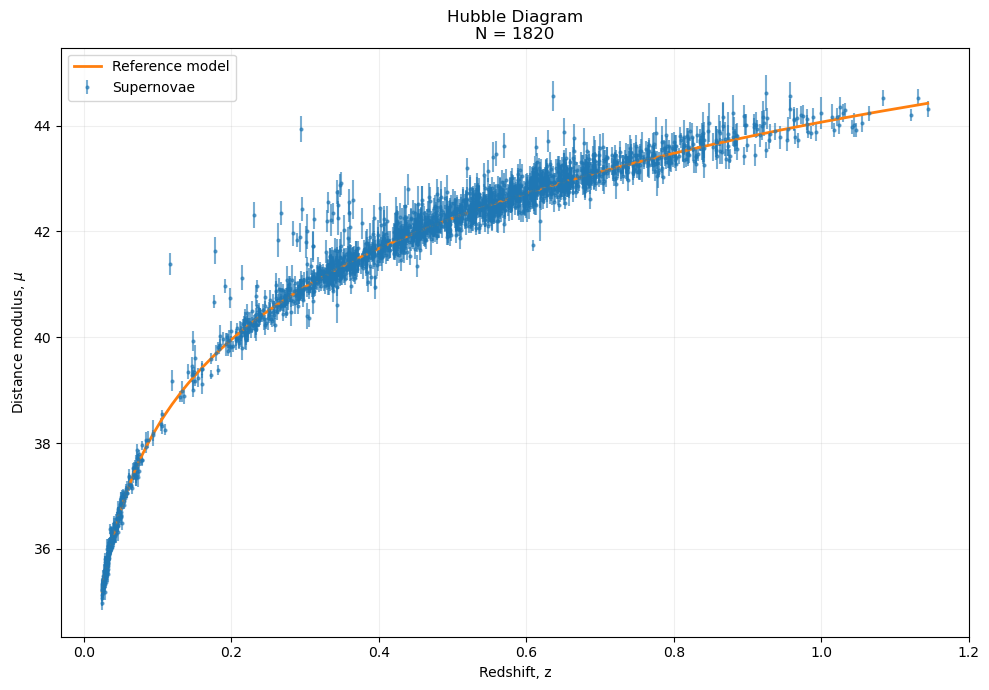

In [28]:
plt.figure(figsize=(10, 7))

sample = all_samples["all"]

plt.errorbar(
    sample["zHD"],
    sample["MU"],
    yerr=sample["MUERR"],
    fmt=".",
    markersize=4,
    alpha=0.6,
    capsize=0,
    label="Supernovae"
)

model = sample.sort_values("zHD")

plt.plot(
    model["zHD"],
    model["MUMODEL"],
    linewidth=2,
    label="Reference model"
)

plt.xlabel("Redshift, z")
plt.ylabel(r"Distance modulus, $\mu$")
plt.title(f"Hubble Diagram\nN = {len(sample)}")
plt.grid(alpha=0.2)
plt.legend()

plt.tight_layout()
plt.show()

## Compare low- and high-redshift samples

Creates Hubble diagrams for the low- and high-redshift subsets to compare how the observations agree with the reference cosmology.

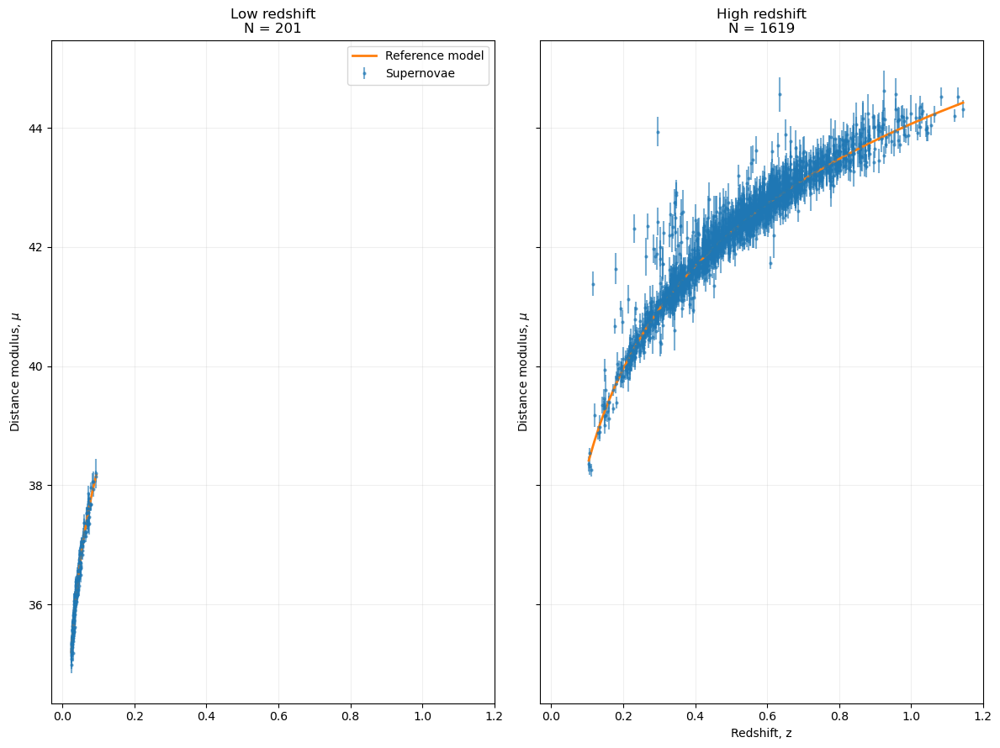

In [6]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 9),
    sharex=True,
    sharey=True
)

for ax, (title, sample) in zip(axes.flat, z_samples.items()):

    # Plot measured distance moduli.
    ax.errorbar(
        sample["zHD"],
        sample["MU"],
        yerr=sample["MUERR"],
        fmt=".",
        markersize=4,
        alpha=0.6,
        capsize=0,
        label="Supernovae"
    )

    # Plot the reference cosmological model.
    model = sample.sort_values("zHD")

    ax.plot(
        model["zHD"],
        model["MUMODEL"],
        linewidth=2,
        label="Reference model"
    )

    ax.set_title(f"{title}\nN = {len(sample)}")
    ax.set_ylabel(r"Distance modulus, $\mu$")
    ax.grid(alpha=0.2)


axes[1].set_xlabel("Redshift, z")
axes[0].legend()


plt.tight_layout()
plt.show()

## Compare host galaxy mass

Creates Hubble diagrams split by both redshift and host galaxy stellar mass, allowing any mass-dependent trends to be visually inspected.

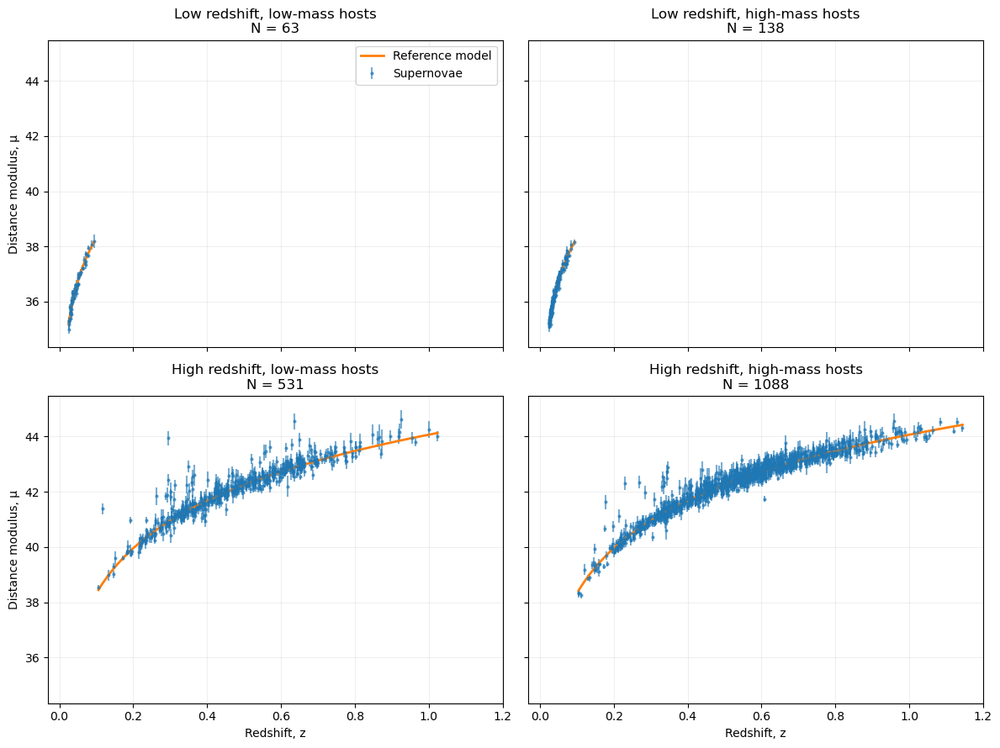

In [7]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9),
    sharex=True,
    sharey=True
)

for ax, (title, sample) in zip(axes.flat, z_m_samples.items()):

    # Plot measured distance moduli.
    ax.errorbar(
        sample["zHD"],
        sample["MU"],
        yerr=sample["MUERR"],
        fmt=".",
        markersize=4,
        alpha=0.6,
        capsize=0,
        label="Supernovae"
    )

    # Plot the reference cosmological model.
    model = sample.sort_values("zHD")

    ax.plot(
        model["zHD"],
        model["MUMODEL"],
        linewidth=2,
        label="Reference model"
    )

    ax.set_title(f"{title}\nN = {len(sample)}")
    ax.grid(alpha=0.2)

axes[0, 0].set_ylabel("Distance modulus, μ")
axes[1, 0].set_ylabel("Distance modulus, μ")

axes[1, 0].set_xlabel("Redshift, z")
axes[1, 1].set_xlabel("Redshift, z")

axes[0, 0].legend()

plt.tight_layout()
plt.show()

## Compare host galaxy star formation rate

Plots Hubble diagrams separated by redshift and host galaxy star formation rate (SFR) to investigate possible environmental effects.

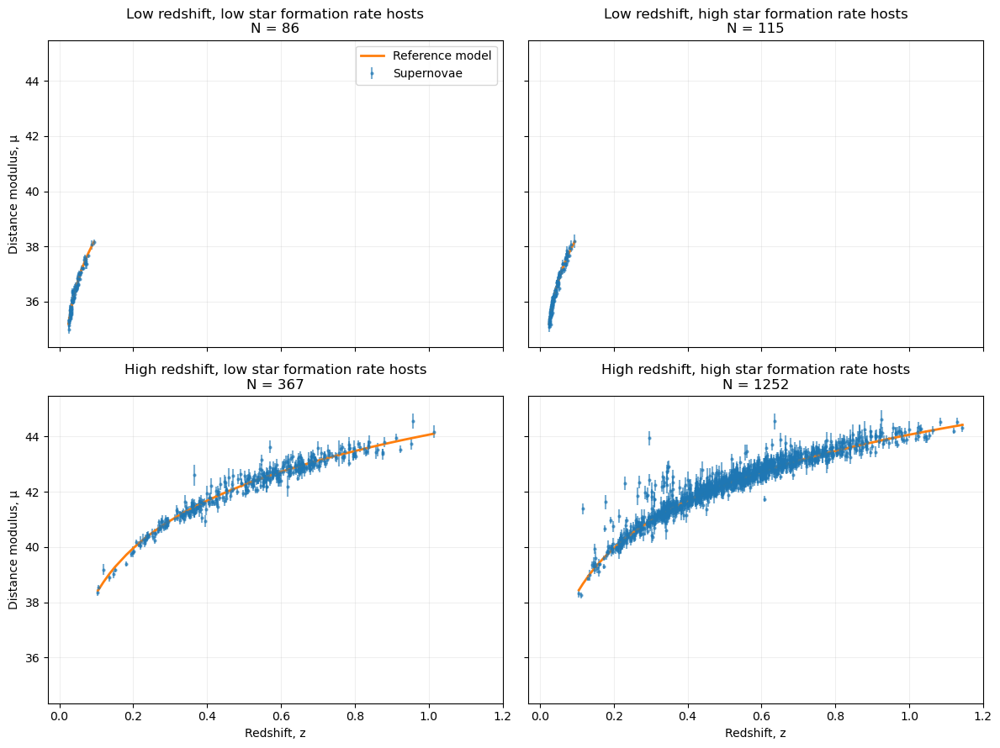

In [8]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9),
    sharex=True,
    sharey=True
)

for ax, (title, sample) in zip(axes.flat, z_SFR_samples.items()):

    # Plot measured distance moduli.
    ax.errorbar(
        sample["zHD"],
        sample["MU"],
        yerr=sample["MUERR"],
        fmt=".",
        markersize=4,
        alpha=0.6,
        capsize=0,
        label="Supernovae"
    )

    # Plot the reference cosmological model.
    model = sample.sort_values("zHD")

    ax.plot(
        model["zHD"],
        model["MUMODEL"],
        linewidth=2,
        label="Reference model"
    )

    ax.set_title(f"{title}\nN = {len(sample)}")
    ax.grid(alpha=0.2)

axes[0, 0].set_ylabel("Distance modulus, μ")
axes[1, 0].set_ylabel("Distance modulus, μ")

axes[1, 0].set_xlabel("Redshift, z")
axes[1, 1].set_xlabel("Redshift, z")

axes[0, 0].legend()

plt.tight_layout()
plt.show()

## Compare host galaxy specific star formation rate

Specific star formation rate (sSFR) measures star formation relative to galaxy mass. Compares Hubble diagrams for different sSFR populations at low and high redshift.

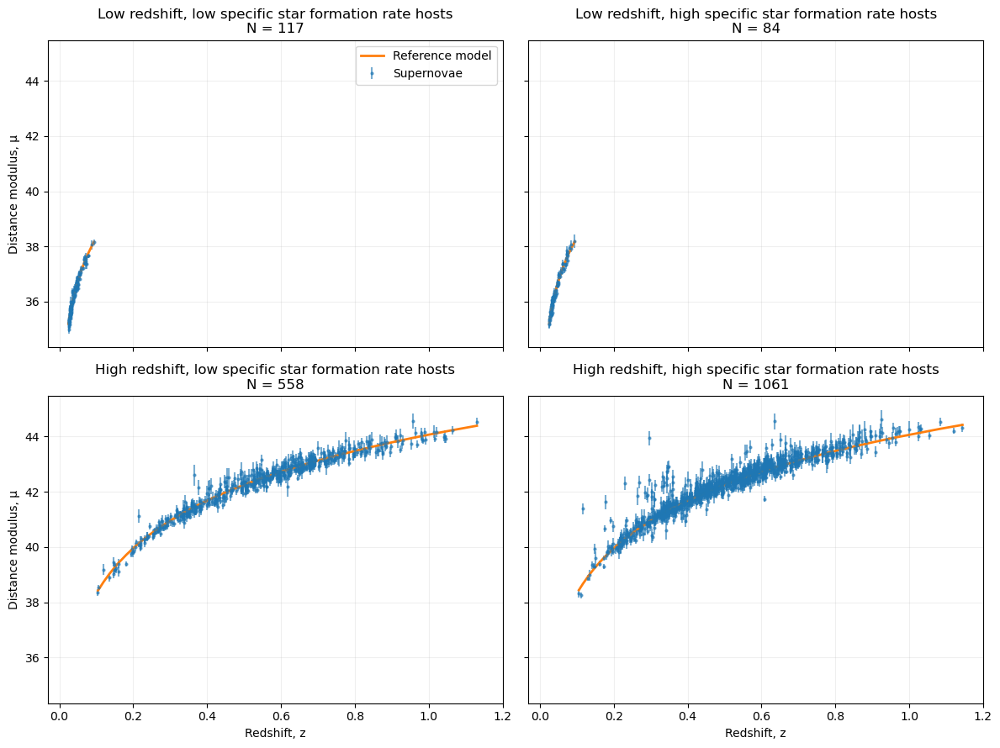

In [9]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9),
    sharex=True,
    sharey=True
)

for ax, (title, sample) in zip(axes.flat, z_sSFR_samples.items()):

    # Plot measured distance moduli.
    ax.errorbar(
        sample["zHD"],
        sample["MU"],
        yerr=sample["MUERR"],
        fmt=".",
        markersize=4,
        alpha=0.6,
        capsize=0,
        label="Supernovae"
    )

    # Plot the reference cosmological model.
    model = sample.sort_values("zHD")

    ax.plot(
        model["zHD"],
        model["MUMODEL"],
        linewidth=2,
        label="Reference model"
    )

    ax.set_title(f"{title}\nN = {len(sample)}")
    ax.grid(alpha=0.2)

axes[0, 0].set_ylabel("Distance modulus, μ")
axes[1, 0].set_ylabel("Distance modulus, μ")

axes[1, 0].set_xlabel("Redshift, z")
axes[1, 1].set_xlabel("Redshift, z")

axes[0, 0].legend()

plt.tight_layout()
plt.show()

## Compare host galaxy color

Compares Hubble diagrams for blue and red host galaxy populations.

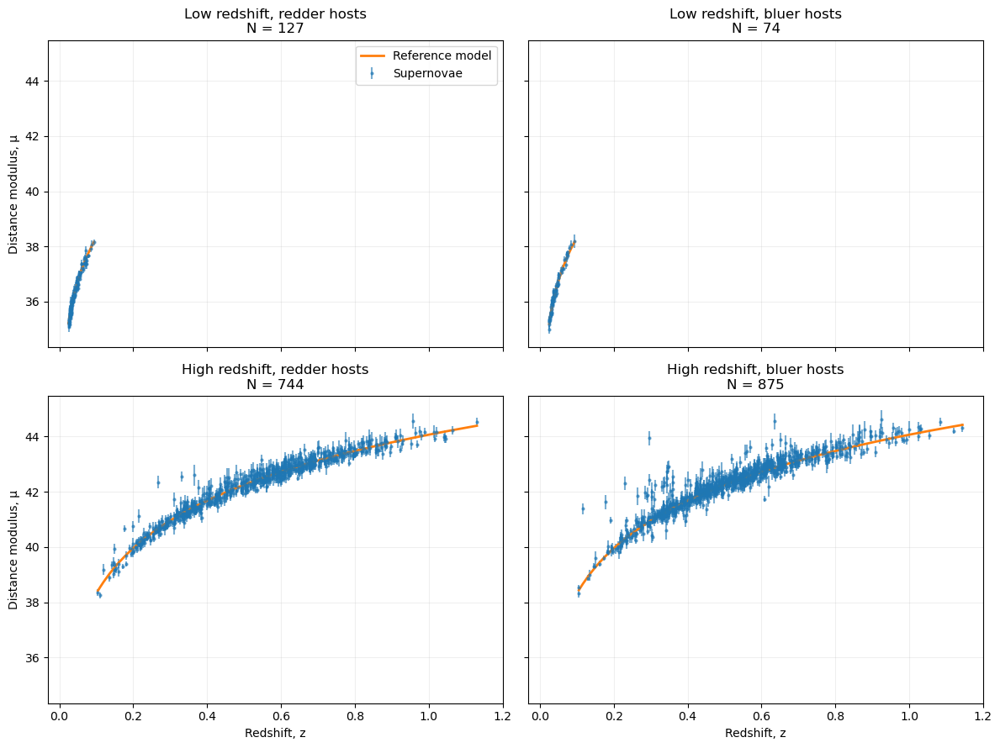

In [10]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9),
    sharex=True,
    sharey=True
)

for ax, (title, sample) in zip(axes.flat, z_c_samples.items()):

    # Plot measured distance moduli.
    ax.errorbar(
        sample["zHD"],
        sample["MU"],
        yerr=sample["MUERR"],
        fmt=".",
        markersize=4,
        alpha=0.6,
        capsize=0,
        label="Supernovae"
    )

    # Plot the reference cosmological model.
    model = sample.sort_values("zHD")

    ax.plot(
        model["zHD"],
        model["MUMODEL"],
        linewidth=2,
        label="Reference model"
    )

    ax.set_title(f"{title}\nN = {len(sample)}")
    ax.grid(alpha=0.2)

axes[0, 0].set_ylabel("Distance modulus, μ")
axes[1, 0].set_ylabel("Distance modulus, μ")

axes[1, 0].set_xlabel("Redshift, z")
axes[1, 1].set_xlabel("Redshift, z")

axes[0, 0].legend()

plt.tight_layout()
plt.show()

In [11]:
def weighted_mean_and_error(values, errors):
    weights = 1.0 / errors**2
    mean = np.average(values, weights=weights)
    error = np.sqrt(1.0 / weights.sum())
    return mean, error

## Hubble residuals versus specific star formation rate

Computes Hubble residuals

$$
\mu_{\rm res} = \mu - \mu_{\rm model}
$$
and examines whether the residuals depend continuously on host galaxy specific star formation rate.

A weighted mean is calculated using inverse-variance weighting, giving more influence to measurements with smaller uncertainties.

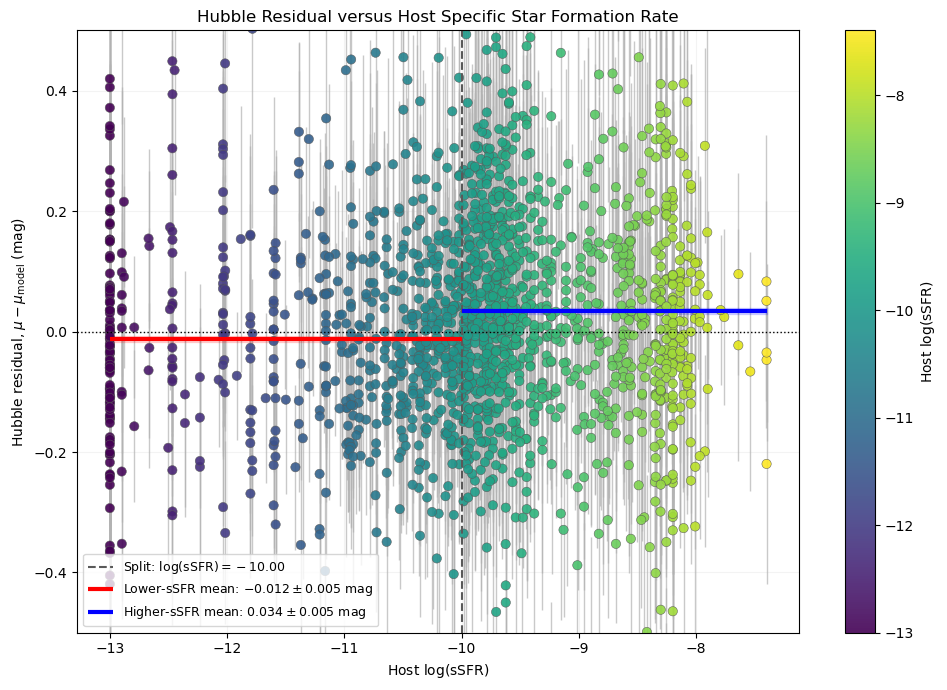

Low-sSFR minus high-sSFR residual step: -0.0465 ± 0.0070 mag


In [12]:
ssfr_data = metadata[["HOST_LOGsSFR", "MU", "MUMODEL", "MUERR"]].dropna().copy()

ssfr_data["MURES"] = ssfr_data["MU"] - ssfr_data["MUMODEL"]

ssfr_cut = -10.0
low_ssfr_mask = ssfr_data["HOST_LOGsSFR"] < ssfr_cut
high_ssfr_mask = ssfr_data["HOST_LOGsSFR"] >= ssfr_cut

# Copy used only for plotting
ssfr_data["HOST_LOGsSFR_plot"] = ssfr_data["HOST_LOGsSFR"].clip(lower=-13)

low_mean, low_mean_err = weighted_mean_and_error(ssfr_data.loc[low_ssfr_mask, "MURES"], ssfr_data.loc[low_ssfr_mask, "MUERR"])

high_mean, high_mean_err = weighted_mean_and_error(ssfr_data.loc[high_ssfr_mask, "MURES"], ssfr_data.loc[high_ssfr_mask, "MUERR"])

ssfr_xmin = ssfr_data["HOST_LOGsSFR_plot"].min()
ssfr_xmax = ssfr_data["HOST_LOGsSFR_plot"].max()

plt.figure(figsize=(10, 7))

plt.errorbar(
    ssfr_data["HOST_LOGsSFR_plot"],
    ssfr_data["MURES"],
    yerr=ssfr_data["MUERR"],
    fmt="none",
    ecolor="0.70",
    elinewidth=1,
    alpha=0.7,
    capsize=0,
    zorder=1
)

scatter = plt.scatter(
    ssfr_data["HOST_LOGsSFR_plot"],
    ssfr_data["MURES"],
    c=ssfr_data["HOST_LOGsSFR_plot"],
    cmap="viridis",
    s=45,
    edgecolor="0.35",
    linewidth=0.4,
    alpha=0.9,
    zorder=2
)

plt.axhline(
    0,
    color="black",
    linestyle=":",
    linewidth=1
)

plt.axvline(
    ssfr_cut,
    color="0.35",
    linestyle="--",
    linewidth=1.5,
    label=(
        rf"Split: "
        rf"$\log(\mathrm{{sSFR}})={ssfr_cut:.2f}$"
    )
)

plt.hlines(
    low_mean,
    xmin=ssfr_xmin,
    xmax=ssfr_cut,
    color="red",
    linewidth=3,
    label=(
        "Lower-sSFR mean: "
        rf"${low_mean:.3f}\pm{low_mean_err:.3f}$ mag"
    )
)

plt.fill_between(
    [ssfr_xmin, ssfr_cut],
    low_mean - low_mean_err,
    low_mean + low_mean_err,
    color="red",
    alpha=0.15
)

plt.hlines(
    high_mean,
    xmin=ssfr_cut,
    xmax=ssfr_xmax,
    color="blue",
    linewidth=3,
    label=(
        "Higher-sSFR mean: "
        rf"${high_mean:.3f}\pm{high_mean_err:.3f}$ mag"
    )
)

plt.fill_between(
    [ssfr_cut, ssfr_xmax],
    high_mean - high_mean_err,
    high_mean + high_mean_err,
    color="blue",
    alpha=0.15
)

colorbar = plt.colorbar(scatter)
colorbar.set_label(r"Host $\log(\mathrm{sSFR})$")

plt.xlabel(r"Host $\log(\mathrm{sSFR})$")
plt.ylabel(
    r"Hubble residual, "
    r"$\mu-\mu_{\mathrm{model}}$ (mag)"
)
plt.title(
    "Hubble Residual versus Host Specific Star Formation Rate"
)

plt.ylim(
    [-0.5, 0.5]
)

plt.grid(alpha=0.15)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

ssfr_step = low_mean - high_mean

ssfr_step_err = np.sqrt(low_mean_err**2 + high_mean_err**2)

print(
    "Low-sSFR minus high-sSFR residual step: "
    f"{ssfr_step:.4f} ± {ssfr_step_err:.4f} mag"
)

# set <-13 to -13

## Hubble residuals versus host galaxy color

Ccomputes Hubble residuals as a function of host galaxy color.

The sample is split at the median host color into bluer and redder galaxies. Weighted average residuals and their uncertainties are calculated to determine whether a significant color step is present.

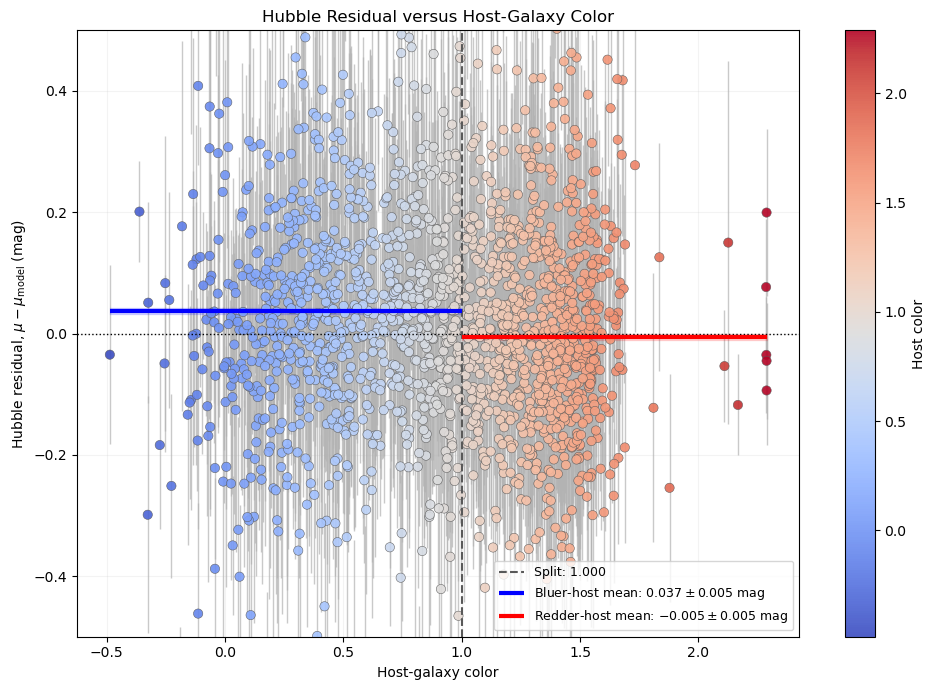

Redder minus bluer residual step: -0.0421 ± 0.0069 mag


In [13]:
color_data = metadata[["HOST_COLOR", "MU", "MUMODEL", "MUERR"]].dropna().copy()

color_data["MURES"] = color_data["MU"] - color_data["MUMODEL"]

color_cut = 1.0

bluer_mask = color_data["HOST_COLOR"] < color_cut
redder_mask = color_data["HOST_COLOR"] >= color_cut

blue_mean, blue_mean_err = weighted_mean_and_error(color_data.loc[bluer_mask, "MURES"], color_data.loc[bluer_mask, "MUERR"])

red_mean, red_mean_err = weighted_mean_and_error(color_data.loc[redder_mask, "MURES"], color_data.loc[redder_mask, "MUERR"])

color_xmin = color_data["HOST_COLOR"].min()
color_xmax = color_data["HOST_COLOR"].max()

plt.figure(figsize=(10, 7))

plt.errorbar(
    color_data["HOST_COLOR"],
    color_data["MURES"],
    yerr=color_data["MUERR"],
    fmt="none",
    ecolor="0.70",
    elinewidth=1,
    alpha=0.7,
    capsize=0,
    zorder=1
)

scatter = plt.scatter(
    color_data["HOST_COLOR"],
    color_data["MURES"],
    c=color_data["HOST_COLOR"],
    cmap="coolwarm",
    s=45,
    edgecolor="0.35",
    linewidth=0.4,
    alpha=0.9,
    zorder=2
)

plt.axhline(
    0,
    color="black",
    linestyle=":",
    linewidth=1
)

plt.axvline(
    color_cut,
    color="0.35",
    linestyle="--",
    linewidth=1.5,
    label=f"Split: {color_cut:.3f}"
)

plt.hlines(
    blue_mean,
    xmin=color_xmin,
    xmax=color_cut,
    color="blue",
    linewidth=3,
    label=(
        "Bluer-host mean: "
        rf"${blue_mean:.3f}\pm{blue_mean_err:.3f}$ mag"
    )
)

plt.fill_between(
    [color_xmin, color_cut],
    blue_mean - blue_mean_err,
    blue_mean + blue_mean_err,
    color="blue",
    alpha=0.15
)

plt.hlines(
    red_mean,
    xmin=color_cut,
    xmax=color_xmax,
    color="red",
    linewidth=3,
    label=(
        "Redder-host mean: "
        rf"${red_mean:.3f}\pm{red_mean_err:.3f}$ mag"
    )
)

plt.fill_between(
    [color_cut, color_xmax],
    red_mean - red_mean_err,
    red_mean + red_mean_err,
    color="red",
    alpha=0.15
)

colorbar = plt.colorbar(scatter)
colorbar.set_label("Host color")

plt.xlabel("Host-galaxy color")
plt.ylabel(
    r"Hubble residual, "
    r"$\mu-\mu_{\mathrm{model}}$ (mag)"
)
plt.title(
    "Hubble Residual versus Host-Galaxy Color"
)

plt.ylim([-0.5, 0.5])

plt.grid(alpha=0.15)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

color_step = red_mean - blue_mean

color_step_err = np.sqrt(red_mean_err**2 + blue_mean_err**2)

print(
    "Redder minus bluer residual step: "
    f"{color_step:.4f} ± {color_step_err:.4f} mag"
)

# Do these same plots fot ZTF data - ZTF doesn't go high enough redshift so only fit H0 and pick values for Omega_M and Omega_Lambda. H0 shifts curve up and down.
# Plot host color vs sSFR (should be very correlated)
# Plot host color vs redshift, look for trend (strong trend not ok, needs correction)

# Cosmology
 # mu_obs = 5 log d_l(z_HD) + 25
 # d_L(z) = f(z; H_0, Omega_M, Omega_Lambda)
 #Cosmology = LAMBDACDM(H0=x, OM=y, OLambda=z)
 # Pick values of H0, Omega_M, Omega_Lambda and use MCMC to find best fit
 # Draw lines w/ different values (mu_pred)
 # Marginzlize over H0 to move curve up and down
 # Make contour plot of Omega_M Omega_Lambda
 # Do one plot for red and one for blue. then plot contours on top of each other
 # Make corner plots
# Simpler thing to try first is do flat LCDM instead of LCDM (Omega_M + Omega_Lambda = 1) f(z; H_0, Omega_M)
# emcee
# Make Hubble diagrams with different values if H0 and Omega_M and see what looks good and not (trial and error)
# lum dist in astropy does integral

# Chi^2 = (mu_obs - mu_pred)^2 / (sigma_obs)^2
# MCMC minimizes function, likelihood l = e^-(chi^2 / 2) or log likelihood l = - chi^2 / 2

# priors - Omega_Lambda so hight compared to Omega_M where if u go back into the history of the univserse, there was no big bang. prior doesn't let Omega_Lambda go very high or below 0. H_0 > 0

# Suspect higher mass hosts are redder and have lower SFR. For Pantheon+ can only do color comparison cause no mass or SFR data.
# Separate hosts on some parameter, use c, host mass, SFR. For Pantheon we only have host mass so make sure to also do that for DES. all these parameters are corrleated so plot all of them

# IN GENERAL, MAKE CONTOUR PLOTS FOR DES AND PANTHEON SEPARATED BY HOST PARAMETERS. look in papers to see how they split especially mass (10).

# ztf set Omega_M to .3 and Omega_Lambda to .7. dont fit these cause not high redshift

### Host Property Correlations

Compare several DES host-galaxy properties to check for correlations between them. The correlation coefficient, $r$, is calculated for each comparison to quantify the strength and direction of the relationship.

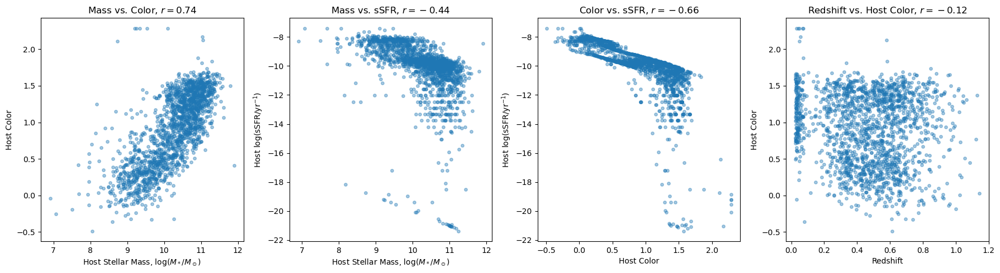

In [14]:
columns = ["HOST_LOGMASS", "HOST_COLOR", "HOST_LOGsSFR", "zHD"]

host_data = metadata[columns].replace([np.inf, -np.inf], np.nan).dropna()

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Host mass vs. host color
axes[0].scatter(
    host_data["HOST_LOGMASS"],
    host_data["HOST_COLOR"],
    s=15,
    alpha=0.4
)

mass_color_r = host_data["HOST_LOGMASS"].corr(host_data["HOST_COLOR"])

axes[0].set_xlabel(r"Host Stellar Mass, $\log(M_*/M_\odot)$")
axes[0].set_ylabel("Host Color")
axes[0].set_title(rf"Mass vs. Color, $r={mass_color_r:.2f}$")


# Host mass vs. host sSFR
axes[1].scatter(
    host_data["HOST_LOGMASS"],
    host_data["HOST_LOGsSFR"],
    s=15,
    alpha=0.4
)

mass_ssfr_r = host_data["HOST_LOGMASS"].corr(host_data["HOST_LOGsSFR"])

axes[1].set_xlabel(r"Host Stellar Mass, $\log(M_*/M_\odot)$")
axes[1].set_ylabel(r"Host $\log(\mathrm{sSFR}/\mathrm{yr}^{-1})$")
axes[1].set_title(rf"Mass vs. sSFR, $r={mass_ssfr_r:.2f}$")


# Host color vs. host sSFR
axes[2].scatter(
    host_data["HOST_COLOR"],
    host_data["HOST_LOGsSFR"],
    s=15,
    alpha=0.4
)

color_ssfr_r = host_data["HOST_COLOR"].corr(host_data["HOST_LOGsSFR"])

axes[2].set_xlabel("Host Color")
axes[2].set_ylabel(r"Host $\log(\mathrm{sSFR}/\mathrm{yr}^{-1})$")
axes[2].set_title(rf"Color vs. sSFR, $r={color_ssfr_r:.2f}$")

# Host color vs. redshift
axes[3].scatter(
    host_data["zHD"],
    host_data["HOST_COLOR"],
    s=15,
    alpha=0.4
)

color_z_r = host_data["zHD"].corr(host_data["HOST_COLOR"])

axes[3].set_xlabel("Redshift")
axes[3].set_ylabel("Host Color")
axes[3].set_title(rf"Redshift vs. Host Color, $r={color_z_r:.2f}$")

plt.tight_layout()
plt.show()

# Cosmological Parameter Fitting

This section contains the MCMC analysis. The workflow is organized in execution order:

1. Define the likelihood, priors, and helper functions.
2. Build the non-clipped analysis samples.
3. Run all non-clipped 2D, 3D, 5D, and 6D fits.
4. Use the non-clipped 5D and 6D fits to define the 2.5-sigma clipped samples.
5. Run the clipped fits.
6. Make the final Hubble diagrams.

### Covariance Matrix

The light-curve fitter simultaneously determines three light-curve parameters:

* $x_0$, which is converted into the apparent magnitude (m_B),
* $x_1$, the stretch parameter,
* $c$, the color parameter.

Because these parameters are fitted simultaneously, their uncertainties are generally correlated. These correlations are described by the covariance matrix

$$
\begin{pmatrix}
\sigma_{x_0}^2 &
\mathrm{Cov}(x_0,x_1) &
\mathrm{Cov}(x_0,c) \\
\mathrm{Cov}(x_1,x_0) &
\sigma_{x_1}^2 &
\mathrm{Cov}(x_1,c) \\
\mathrm{Cov}(c,x_0) &
\mathrm{Cov}(c,x_1) &
\sigma_c^2
\end{pmatrix}.
$$

The diagonal elements are the variances of the fitted parameters, while the off-diagonal elements are the covariances, which quantify how the uncertainties in two parameters are correlated.

The metadata file stores the off-diagonal covariance terms as the columns

* `COV_x1_x0`,
* `COV_c_x0`,
* `COV_x1_c`.

Since the cosmological analysis uses the apparent magnitude $m_B$ rather than the normalization parameter $x_0$, the covariance terms involving $x_0$ are transformed using

$$
m_B = -2.5\log_{10}(x_0) + \mathrm{constant},
$$

whose derivative is

$$
\frac{dm_B}{dx_0} = -\frac{2.5}{x_0\ln10}.
$$

Applying standard uncertainty propagation gives

$$
\mathrm{Cov}(m_B,x_1) = \frac{dm_B}{dx_0} \mathrm{Cov}(x_0,x_1),
$$

and

$$
\mathrm{Cov}(m_B,c) = \frac{dm_B}{dx_0} \mathrm{Cov}(x_0,c).
$$

These transformed covariance terms are then used when propagating the uncertainty in the reconstructed distance modulus,

$$
\mu_{\rm obs} = m_B - M_B + \alpha x_1 - \beta c + \gamma HM,
$$

ensuring that the likelihood correctly accounts for the correlated uncertainties in the light-curve parameters.


In [29]:
# FIXED
H_0 = 70.0
sigma_int = 0.10

def log_prior(theta):
    """
    Defines which parameter values the MCMC is allowed to explore.
    Returns:
        0.0      for an allowed parameter combination
        -np.inf  for a forbidden parameter combination
    Because the posterior is evaluated in logarithmic form, returning -np.inf makes the posterior probability exactly zero.
    """
    nparam = len(theta)
    
    if nparam == 5:
        M_B, Omega_M, Omega_Lambda, alpha, beta = theta
        if (
            -20.5 < M_B < -18.0
            and 0.0 < Omega_M < 1.5 
            and -1.5 <= Omega_Lambda < 1.5
            and 0.0 < alpha < 0.5
            and 0.0 < beta < 6.0
        ):
            return 0.0
        else:
            return -np.inf

    elif nparam == 6:
        M_B, Omega_M, Omega_Lambda, alpha, beta, gamma = theta
        if (
            -20.5 < M_B < -18.0
            and 0.0 < Omega_M < 1.5 
            and -1.5 <= Omega_Lambda < 1.5
            and 0.0 < alpha < 0.5
            and 0.0 < beta < 6.0
            and -0.5 < gamma < 0.5
        ):
            return 0.0
        else:
            return -np.inf
    else:
        raise ValueError("Unexpected size? len(theta) should be 5 or 6")    


def log_likelihood(theta, data):
    """
    Compares the measured distance moduli with the distance moduli predicted by the proposed cosmological parameters.
    Theta contains the proposed cosmological parameters.
    Data is a tuple containing:
        redshift
        observed distance modulus
        distance-modulus uncertainty
    """
    nparam = len(theta)

    if nparam == 5:
        M_B, Omega_M, Omega_Lambda, alpha, beta = theta
        (
            redshift,
            mB,
            x1,
            c,
            host_logmass,
            mB_err,
            x1_err,
            c_err,
            cov_mB_x1,
            cov_mB_c,
            cov_x1_c,
            muerr_vpec,
            lensdmuerr
        ) = data
        mu_obs = mB - M_B + alpha*x1 - beta*c
        variance = mB_err**2 + alpha**2*x1_err**2 + beta**2*c_err**2 + 2.0*alpha*cov_mB_x1 - 2.0*beta*cov_mB_c - 2.0*alpha*beta*cov_x1_c + muerr_vpec**2 + lensdmuerr**2 + sigma_int**2

    elif nparam == 6:
        M_B, Omega_M, Omega_Lambda, alpha, beta, gamma = theta
        (
            redshift,
            mB,
            x1,
            c,
            host_logmass,
            mB_err,
            x1_err,
            c_err,
            cov_mB_x1,
            cov_mB_c,
            cov_x1_c,
            muerr_vpec,
            lensdmuerr
        ) = data
        HM = (host_logmass >= mass_cut).astype(float)
        mu_obs = mB - M_B + alpha*x1 - beta*c + gamma*HM
        variance = mB_err**2 + alpha**2*x1_err**2 + beta**2*c_err**2 + 2.0*alpha*cov_mB_x1 - 2.0*beta*cov_mB_c - 2.0*alpha*beta*cov_x1_c + muerr_vpec**2 + lensdmuerr**2 + sigma_int**2
    else:
        raise ValueError("Unexpected size? len(theta) should be 5 or 6")    


    # Construct Astropy LambdaCDM cosmology using the current proposed values of H0, Omega_M, and Omega_Lambda.
    # H0: Present-day Hubble expansion rate in km/s/Mpc.
    # Om0: Present-day matter density parameter Omega_M.
    # Ode0: Present-day dark-energy density parameter Omega_Lambda.
    
    cosmology = LambdaCDM(
        H0=H_0,
        Om0=Omega_M,
        Ode0=Omega_Lambda
    )
    
    with np.errstate(invalid="ignore"):
        mu_pred = cosmology.distmod(redshift).value
    
    if not np.all(np.isfinite(mu_pred)):
        return -np.inf
    
    residuals = mu_obs - mu_pred
    
    if np.any(~np.isfinite(variance)) or np.any(variance <= 0.0):
        return -np.inf
    
    loglike = -0.5 * np.sum(np.log(2.0 * np.pi * variance) + residuals**2 / variance)

    return loglike

def log_posterior(theta, data):
    logpr = log_prior(theta)
    if logpr == -np.inf:
        return logpr
    else:
        return logpr + log_likelihood(theta, data)

def make_data_tuple(sample, nparam):
    if nparam in (5, 6):
        return (
            sample["zHD"].to_numpy(),
            sample["mB"].to_numpy(),
            sample["x1"].to_numpy(),
            sample["c"].to_numpy(),
            sample["HOST_LOGMASS"].to_numpy(),
            sample["mBERR"].to_numpy(),
            sample["x1ERR"].to_numpy(),
            sample["cERR"].to_numpy(),
            sample["COV_mB_x1"].to_numpy(),
            sample["COV_mB_c"].to_numpy(),
            sample["COV_x1_c"].to_numpy(),
            sample["MUERR_VPEC"].to_numpy(),
            sample["LENSDMUERR"].to_numpy()
        )

    else:
        raise ValueError("nparam should be 5 or 6")

def make_starting_positions(initial_guess, nwalkers, random_seed=None):
    rng = np.random.default_rng(random_seed)
    ndim = len(initial_guess)

    if ndim == 5:
        scales = np.array([0.02, 0.02, 0.02, 0.01, 0.10])
    
    elif ndim == 6:
        scales = np.array([0.02, 0.02, 0.02, 0.01, 0.10, 0.01])

    else:
        raise ValueError("initial_guess must contain 5 or 6 parameters")

    positions = initial_guess + scales * rng.normal(size=(nwalkers, ndim))

    for i in range(nwalkers):
        while not np.isfinite(log_prior(positions[i])):
            positions[i] = initial_guess + scales * rng.normal(size=ndim)

    return positions


def run_mcmc(data, initial_guess, nwalkers=32, nsteps=5000, burnin=1000, thin=1, random_seed=None):
    ndim = len(initial_guess)

    if nwalkers < 2 * ndim:
        raise ValueError("nwalkers must be at least twice ndim")

    if burnin >= nsteps:
        raise ValueError("burnin must be smaller than nsteps")

    starting_positions = make_starting_positions(
        initial_guess,
        nwalkers,
        random_seed=random_seed
    )

    sampler = emcee.EnsembleSampler(
        nwalkers,
        ndim,
        log_posterior,
        args=(data,),
        threads = 8
    )

    sampler.run_mcmc(
        starting_positions,
        nsteps,
        progress=True
    )

    samples = sampler.get_chain(
        discard=burnin,
        thin=thin,
        flat=True
    )

    return sampler, samples


def summarize_samples(name, samples, filename=None):
    if samples.shape[1] == 5:
        labels = ["M_B", "Omega_M", "Omega_Lambda", "alpha", "beta"]
    elif samples.shape[1] == 6:
        labels = ["M_B", "Omega_M", "Omega_Lambda", "alpha", "beta", "gamma"]
    else:
        raise ValueError("Samples must contain 5 or 6 columns")

    percentiles = np.percentile(samples, [16, 50, 84], axis=0)

    print(f"\n{name}")

    summary = {}
    summary_lines = [name]

    for i, label in enumerate(labels):
        median = percentiles[1, i]
        lower = median - percentiles[0, i]
        upper = percentiles[2, i] - median

        summary[label] = {
            "median": median,
            "minus": lower,
            "plus": upper
        }

        line = f"{label} = {median:.4f} -{lower:.4f} +{upper:.4f}"

        print(line)
        summary_lines.append(line)

    if filename is not None:
        filename = Path(filename)
        filename.parent.mkdir(parents=True, exist_ok=True)

        summary_text = "\n".join(summary_lines)

        with open(filename, "w") as f:
            f.write(summary_text)

    return summary

def get_corner_ranges(samples1, samples2):
    combined = np.vstack([samples1, samples2])
    ranges = []

    for i in range(combined.shape[1]):
        low = np.min(combined[:, i])
        high = np.max(combined[:, i])
        padding = 0.05 * (high - low)

        ranges.append((low - padding, high + padding))

    return ranges

def plot_overlaid_corner(samples_1, samples_2, label_1, label_2, title, color_1, color_2, filename=None):
    
    ndim = samples_1.shape[1]

    if samples_2.shape[1] != ndim:
        raise ValueError("Both sample arrays must have the same number of columns")

    corner_ranges = get_corner_ranges(samples_1, samples_2)
    
    if ndim == 5:
        parameter_labels = [
            r"$M_B$",
            r"$\Omega_M$",
            r"$\Omega_\Lambda$",
            r"$\alpha$",
            r"$\beta$",
        ]
    
    elif ndim == 6:
        parameter_labels = [
            r"$M_B$",
            r"$\Omega_M$",
            r"$\Omega_\Lambda$",
            r"$\alpha$",
            r"$\beta$",
            r"$\gamma$"
        ]

    else:
        raise ValueError("Samples must contain 5 or 6 columns")
    
    figure = corner.corner(
        samples_1,
        labels=parameter_labels,
        range=corner_ranges,
        color=color_1,
        levels=(0.683, 0.954),
        plot_datapoints=False,
        plot_density=True,
        fill_contours=False,
        smooth=1.0,
        show_titles=False,
        title_fmt=".3f"
    )

    corner.corner(
        samples_2,
        labels=parameter_labels,
        range=corner_ranges,
        color=color_2,
        levels=(0.683, 0.954),
        plot_datapoints=False,
        plot_density=True,
        fill_contours=False,
        smooth=1.0,
        show_titles=False,
        fig=figure
    )

    legend_handles = [
        Line2D([0], [0], color=color_1, linewidth=2, label=label_1),
        Line2D([0], [0], color=color_2, linewidth=2, label=label_2)
    ]

    figure.legend(
        handles=legend_handles,
        loc="upper right",
        frameon=False
    )

    figure.suptitle(title, fontsize=14, y=1.02)
    #figure.subplots_adjust(top=0.90)

    if filename is not None:
        figure.savefig(
            filename,
            dpi=300,
            bbox_inches="tight"
        )   
    plt.show()

# DIAGNOSTICS
def plot_x1_diagnostic(sample, M_B, Omega_M, Omega_Lambda, alpha, beta, gamma, color="black", title=r"$x_1$ diagnostic", filename=None):
    data = sample[["zHD", "mB", "x1", "c", "HOST_LOGMASS"]].dropna().copy()

    cosmology = LambdaCDM(H0=H_0, Om0=Omega_M, Ode0=Omega_Lambda)
    data["MU_MODEL"] = cosmology.distmod(data["zHD"].to_numpy()).value

    HM = (data["HOST_LOGMASS"] >= mass_cut).astype(float)

    data["y"] = data["mB"] - M_B - data["MU_MODEL"] - beta*data["c"] + gamma*HM

    x1_line = np.linspace(data["x1"].min(), data["x1"].max(), 200)

    plt.figure(figsize=(7, 5))

    plt.scatter(
        data["x1"],
        data["y"],
        s=15,
        alpha=0.4,
        color=color
    )

    plt.plot(
        x1_line,
        -alpha*x1_line,
        linewidth=2,
        color=color,
        label=rf"$\alpha={alpha:.3f}$"
    )

    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$m_B-M_B-\mu_{\rm model}-\beta c+\gamma HM$")
    plt.title(title)
    plt.legend()
    plt.tight_layout()

    if filename is not None:
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()

def plot_c_diagnostic(sample, M_B, Omega_M, Omega_Lambda, alpha, beta, gamma, color="black", title=r"$c$ diagnostic", filename=None):
    data = sample[["zHD", "mB", "x1", "c", "HOST_LOGMASS"]].dropna().copy()

    cosmology = LambdaCDM(H0=H_0, Om0=Omega_M, Ode0=Omega_Lambda)
    data["MU_MODEL"] = cosmology.distmod(data["zHD"].to_numpy()).value

    HM = (data["HOST_LOGMASS"] >= mass_cut).astype(float)

    data["y"] = data["mB"] - M_B - data["MU_MODEL"] + alpha*data["x1"] + gamma*HM

    c_line = np.linspace(data["c"].min(), data["c"].max(), 200)

    plt.figure(figsize=(7, 5))

    plt.scatter(
        data["c"],
        data["y"],
        s=15,
        alpha=0.4,
        color=color
    )

    plt.plot(
        c_line,
        beta*c_line,
        linewidth=2,
        color=color,
        label=rf"$\beta={beta:.3f}$"
    )

    plt.xlabel(r"$c$")
    plt.ylabel(r"$m_B-M_B-\mu_{\rm model}+\alpha x_1+\gamma HM$")
    plt.title(title)
    plt.legend()
    plt.tight_layout()

    if filename is not None:
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()

def plot_gamma_diagnostic(sample, M_B, Omega_M, Omega_Lambda, alpha, beta, gamma, color="black", title=r"$\gamma$ diagnostic", filename=None):
    data = sample[["zHD", "mB", "x1", "c", "HOST_LOGMASS"]].dropna().copy()

    cosmology = LambdaCDM(H0=H_0, Om0=Omega_M, Ode0=Omega_Lambda)
    data["MU_MODEL"] = cosmology.distmod(data["zHD"].to_numpy()).value

    data["y"] = data["mB"] - M_B - data["MU_MODEL"] + alpha*data["x1"] - beta*data["c"]

    low = data["HOST_LOGMASS"] < mass_cut
    high = data["HOST_LOGMASS"] >= mass_cut

    plt.figure(figsize=(7, 5))

    plt.scatter(
        data.loc[low, "HOST_LOGMASS"],
        data.loc[low, "y"],
        s=15,
        alpha=0.4,
        color=color,
        label="Low mass"
    )

    plt.scatter(
        data.loc[high, "HOST_LOGMASS"],
        data.loc[high, "y"],
        s=15,
        alpha=0.4,
        color=color,
        label="High mass"
    )

    plt.hlines(
        0,
        data["HOST_LOGMASS"].min(),
        mass_cut,
        color=color,
        linewidth=2
    )

    plt.hlines(
        -gamma,
        mass_cut,
        data["HOST_LOGMASS"].max(),
        color=color,
        linewidth=2,
        label=rf"$\gamma={gamma:.3f}$"
    )

    plt.axvline(
        mass_cut,
        color="black",
        linestyle="--",
        linewidth=1
    )

    plt.xlabel(r"Host Stellar Mass, $\log(M_*/M_\odot)$")
    plt.ylabel(r"$m_B-M_B-\mu_{\rm model}+\alpha x_1-\beta c$")
    plt.title(title)
    plt.legend()
    plt.tight_layout()

    if filename is not None:
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()

def plot_mcmc_diagnostics(sample, samples, title="MCMC diagnostics", filename_prefix="DES", clipped=False):
    ndim = samples.shape[1]

    if clipped:
        if ndim == 5:
            diagnostics_dir = clipped_5d_dir
        elif ndim == 6:
            diagnostics_dir = clipped_6d_dir
        else:
            raise ValueError("Diagnostics only supported for 5D or 6D samples")
    else:
        if ndim == 5:
            diagnostics_dir = nonclipped_5d_dir
        elif ndim == 6:
            diagnostics_dir = nonclipped_6d_dir
        else:
            raise ValueError("Diagnostics only supported for 5D or 6D samples")

    M_B_fit = np.median(samples[:, 0])
    Omega_M_fit = np.median(samples[:, 1])
    Omega_Lambda_fit = np.median(samples[:, 2])
    alpha_fit = np.median(samples[:, 3])
    beta_fit = np.median(samples[:, 4])

    if ndim == 5:
        gamma_fit = 0.0
    else:
        gamma_fit = np.median(samples[:, 5])

    plot_x1_diagnostic(
        sample,
        M_B_fit,
        Omega_M_fit,
        Omega_Lambda_fit,
        alpha_fit,
        beta_fit,
        gamma_fit,
        title=rf"$x_1$ diagnostic: {title}",
        filename=diagnostics_dir / f"{filename_prefix}_x1_diagnostic.png"
    )

    plot_c_diagnostic(
        sample,
        M_B_fit,
        Omega_M_fit,
        Omega_Lambda_fit,
        alpha_fit,
        beta_fit,
        gamma_fit,
        title=rf"$c$ diagnostic: {title}",
        filename=diagnostics_dir / f"{filename_prefix}_c_diagnostic.png"
    )

    if ndim == 6:
        plot_gamma_diagnostic(
            sample,
            M_B_fit,
            Omega_M_fit,
            Omega_Lambda_fit,
            alpha_fit,
            beta_fit,
            gamma_fit,
            title=rf"$\gamma$ diagnostic: {title}",
            filename=diagnostics_dir / f"{filename_prefix}_gamma_diagnostic.png"
        )

def plot_x1_diagnostic_split(sample_low, samples_low, sample_high, samples_high, low_label, high_label, low_color, high_color, title=r"$x_1$ diagnostic", filename=None):
    def prepare(sample, samples):
        M_B = np.median(samples[:, 0])
        Omega_M = np.median(samples[:, 1])
        Omega_Lambda = np.median(samples[:, 2])
        alpha = np.median(samples[:, 3])
        beta = np.median(samples[:, 4])
        gamma = 0.0 if samples.shape[1] == 5 else np.median(samples[:, 5])

        data = sample[["zHD", "mB", "x1", "c", "HOST_LOGMASS"]].dropna().copy()

        cosmology = LambdaCDM(H0=H_0, Om0=Omega_M, Ode0=Omega_Lambda)
        data["MU_MODEL"] = cosmology.distmod(data["zHD"].to_numpy()).value

        HM = (data["HOST_LOGMASS"] >= mass_cut).astype(float)

        data["y"] = data["mB"] - M_B - data["MU_MODEL"] - beta*data["c"] + gamma*HM

        return data, alpha

    low, alpha_low = prepare(sample_low, samples_low)
    high, alpha_high = prepare(sample_high, samples_high)

    plt.figure(figsize=(7, 5))

    plt.scatter(low["x1"], low["y"], s=15, alpha=0.4, label=low_label, color=low_color)
    plt.scatter(high["x1"], high["y"], s=15, alpha=0.4, label=high_label, color=high_color)

    x_min = min(low["x1"].min(), high["x1"].min())
    x_max = max(low["x1"].max(), high["x1"].max())
    x_line = np.linspace(x_min, x_max, 200)

    plt.plot(x_line, -alpha_low*x_line, linewidth=2, label=rf"{low_label}: $\alpha={alpha_low:.3f}$", color=low_color)
    plt.plot(x_line, -alpha_high*x_line, linewidth=2, label=rf"{high_label}: $\alpha={alpha_high:.3f}$", color=high_color)

    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$m_B-M_B-\mu_{\rm model}-\beta c+\gamma HM$")
    plt.title(title)
    plt.legend()
    plt.tight_layout()

    if filename is not None:
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()

def plot_c_diagnostic_split(sample_low, samples_low, sample_high, samples_high, low_label, high_label, low_color, high_color, title=r"$c$ diagnostic", filename=None):
    def prepare(sample, samples):
        M_B = np.median(samples[:, 0])
        Omega_M = np.median(samples[:, 1])
        Omega_Lambda = np.median(samples[:, 2])
        alpha = np.median(samples[:, 3])
        beta = np.median(samples[:, 4])
        gamma = 0.0 if samples.shape[1] == 5 else np.median(samples[:, 5])

        data = sample[["zHD", "mB", "x1", "c", "HOST_LOGMASS"]].dropna().copy()

        cosmology = LambdaCDM(H0=H_0, Om0=Omega_M, Ode0=Omega_Lambda)
        data["MU_MODEL"] = cosmology.distmod(data["zHD"].to_numpy()).value

        HM = (data["HOST_LOGMASS"] >= mass_cut).astype(float)

        data["y"] = data["mB"] - M_B - data["MU_MODEL"] + alpha*data["x1"] + gamma*HM

        return data, beta

    low, beta_low = prepare(sample_low, samples_low)
    high, beta_high = prepare(sample_high, samples_high)

    plt.figure(figsize=(7, 5))

    plt.scatter(low["c"], low["y"], s=15, alpha=0.4, label=low_label, color=low_color)
    plt.scatter(high["c"], high["y"], s=15, alpha=0.4, label=high_label, color=high_color)

    c_min = min(low["c"].min(), high["c"].min())
    c_max = max(low["c"].max(), high["c"].max())
    c_line = np.linspace(c_min, c_max, 200)

    plt.plot(c_line, beta_low*c_line, linewidth=2, label=rf"{low_label}: $\beta={beta_low:.3f}$", color=low_color)
    plt.plot(c_line, beta_high*c_line, linewidth=2, label=rf"{high_label}: $\beta={beta_high:.3f}$", color=high_color)

    plt.xlabel(r"$c$")
    plt.ylabel(r"$m_B-M_B-\mu_{\rm model}+\alpha x_1+\gamma HM$")
    plt.title(title)
    plt.legend()
    plt.tight_layout()

    if filename is not None:
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()

def plot_gamma_diagnostic_split(sample_low, samples_low, sample_high, samples_high, low_label, high_label, low_color, high_color, title=r"$\gamma$ diagnostic", filename=None):
    def prepare(sample, samples):
        M_B = np.median(samples[:, 0])
        Omega_M = np.median(samples[:, 1])
        Omega_Lambda = np.median(samples[:, 2])
        alpha = np.median(samples[:, 3])
        beta = np.median(samples[:, 4])
        gamma = np.median(samples[:, 5])

        data = sample[["zHD", "mB", "x1", "c", "HOST_LOGMASS"]].dropna().copy()

        cosmology = LambdaCDM(H0=H_0, Om0=Omega_M, Ode0=Omega_Lambda)
        data["MU_MODEL"] = cosmology.distmod(data["zHD"].to_numpy()).value

        data["y"] = data["mB"] - M_B - data["MU_MODEL"] + alpha*data["x1"] - beta*data["c"]

        return data, gamma

    low, gamma_low = prepare(sample_low, samples_low)
    high, gamma_high = prepare(sample_high, samples_high)

    plt.figure(figsize=(7, 5))

    plt.scatter(low["HOST_LOGMASS"], low["y"], s=15, alpha=0.4, label=low_label, color=low_color)
    plt.scatter(high["HOST_LOGMASS"], high["y"], s=15, alpha=0.4, label=high_label, color=high_color)

    xmin = min(low["HOST_LOGMASS"].min(), high["HOST_LOGMASS"].min())
    xmax = max(low["HOST_LOGMASS"].max(), high["HOST_LOGMASS"].max())

    plt.hlines(0, xmin, mass_cut, linewidth=2)
    plt.hlines(-gamma_low, mass_cut, xmax, linewidth=2, label=rf"{low_label}: $\gamma={gamma_low:.3f}$", color=low_color)
    plt.hlines(-gamma_high, mass_cut, xmax, linewidth=2, label=rf"{high_label}: $\gamma={gamma_high:.3f}$", color=high_color)

    plt.axvline(mass_cut, linestyle="--", linewidth=1)

    plt.xlabel(r"Host Stellar Mass, $\log(M_*/M_\odot)$")
    plt.ylabel(r"$m_B-M_B-\mu_{\rm model}+\alpha x_1-\beta c$")
    plt.title(title)
    plt.legend()
    plt.tight_layout()

    if filename is not None:
        plt.savefig(filename, dpi=300, bbox_inches="tight")

    plt.show()

def plot_mcmc_diagnostics_split(sample_low, samples_low, sample_high, samples_high, low_label, high_label, low_color, high_color, title="MCMC diagnostics", filename_prefix="DES", clipped=False):
    ndim = samples_low.shape[1]

    if samples_high.shape[1] != ndim:
        raise ValueError("Both MCMC runs must have the same number of dimensions")

    if clipped:
        if ndim == 5:
            diagnostics_dir = clipped_5d_dir
        elif ndim == 6:
            diagnostics_dir = clipped_6d_dir
        else:
            raise ValueError("Diagnostics only supported for 5D or 6D samples")
    else:
        if ndim == 5:
            diagnostics_dir = nonclipped_5d_dir
        elif ndim == 6:
            diagnostics_dir = nonclipped_6d_dir
        else:
            raise ValueError("Diagnostics only supported for 5D or 6D samples")

    plot_x1_diagnostic_split(sample_low, samples_low, sample_high, samples_high, low_label, high_label, low_color, high_color, title=rf"$x_1$ diagnostic: {title}", filename=diagnostics_dir / f"{filename_prefix}_x1_diagnostic.png")

    plot_c_diagnostic_split(sample_low, samples_low, sample_high, samples_high, low_label, high_label, low_color, high_color, title=rf"$c$ diagnostic: {title}", filename=diagnostics_dir / f"{filename_prefix}_c_diagnostic.png")

    if ndim == 6:
        plot_gamma_diagnostic_split(sample_low, samples_low, sample_high, samples_high, low_label, high_label, low_color, high_color, title=rf"$\gamma$ diagnostic: {title}", filename=diagnostics_dir / f"{filename_prefix}_gamma_diagnostic.png")

def plot_burnin_diagnostics(sampler, burnin, title="MCMC burn-in diagnostics", filename_prefix="DES", clipped=False):
    chain = sampler.get_chain()
    ndim = chain.shape[2]

    if clipped:
        if ndim == 5:
            diagnostics_dir = clipped_5d_dir
        elif ndim == 6:
            diagnostics_dir = clipped_6d_dir
        else:
            raise ValueError("Burn-in diagnostics only supported for 5D or 6D samples")
    else:
        if ndim == 5:
            diagnostics_dir = nonclipped_5d_dir
        elif ndim == 6:
            diagnostics_dir = nonclipped_6d_dir
        else:
            raise ValueError("Burn-in diagnostics only supported for 5D or 6D samples")

    if ndim == 5:
        labels = [
            r"$M_B$",
            r"$\Omega_M$",
            r"$\Omega_\Lambda$",
            r"$\alpha$",
            r"$\beta$"
        ]

    elif ndim == 6:
        labels = [
            r"$M_B$",
            r"$\Omega_M$",
            r"$\Omega_\Lambda$",
            r"$\alpha$",
            r"$\beta$",
            r"$\gamma$"
        ]

    for i in range(ndim):
        plt.figure(figsize=(9, 4))

        plt.plot(chain[:, :, i], alpha=0.3)
        plt.axvline(burnin, linestyle="--", linewidth=2)

        plt.xlabel("Step")
        plt.ylabel(labels[i])
        plt.title(f"{title}: {labels[i]}")
        plt.tight_layout()

        plt.savefig(
            diagnostics_dir / f"{filename_prefix}_burnin_{i}.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

## Prepare Analysis Samples

In [30]:
# Analysis cuts
color_cut = 1.0
mass_cut = 10.0
ssfr_cut = -10.0
sigma_cut = 2.5

required_columns = [
    "zHD",
    "MU",
    "MUERR",
    "mB",
    "mBERR",
    "x1",
    "x1ERR",
    "c",
    "cERR",
    "COV_mB_x1",
    "COV_mB_c",
    "COV_x1_c",
    "MUERR_VPEC",
    "LENSDMUERR",
    "HOST_LOGMASS",
    "HOST_LOGSFR",
    "HOST_LOGsSFR",
    "HOST_COLOR"
]

# -------------------------------------------------------------------------------------------
# Main sample
# -------------------------------------------------------------------------------------------
des_sample = metadata[required_columns].replace([np.inf, -np.inf], np.nan).dropna().copy()
des_sample = des_sample[(des_sample["zHD"] > 0) & (des_sample["MUERR"] > 0)].copy()

# -------------------------------------------------------------------------------------------
# Remove rows with invalid covariance information
# -------------------------------------------------------------------------------------------
rho_mB_x1 = des_sample["COV_mB_x1"] / (des_sample["mBERR"] * des_sample["x1ERR"])

rho_mB_c = des_sample["COV_mB_c"] / (des_sample["mBERR"] * des_sample["cERR"])

rho_x1_c = des_sample["COV_x1_c"] / (des_sample["x1ERR"] * des_sample["cERR"])

valid_covariance = (np.isfinite(rho_mB_x1) & np.isfinite(rho_mB_c) & np.isfinite(rho_x1_c) & (np.abs(rho_mB_x1) <= 1.0) & (np.abs(rho_mB_c) <= 1.0) & (np.abs(rho_x1_c) <= 1.0))

des_sample_6d = des_sample[valid_covariance].copy()

des_sample_6d = des_sample_6d[(des_sample_6d["mBERR"] > 0) & (des_sample_6d["x1ERR"] > 0) & (des_sample_6d["cERR"] > 0)].copy()

des_sample_5d = des_sample_6d.copy()

print(f"Main sample: {len(des_sample)}")
print(f"Covariance-clean 5D/6D sample: {len(des_sample_6d)}")
print(f"Invalid covariance rows removed: {len(des_sample) - len(des_sample_6d)}")


Main sample: 1820
Covariance-clean 5D/6D sample: 1810
Invalid covariance rows removed: 10


In [31]:
# -------------------------
# 5D splits
# -------------------------
low_mass_df_5d = des_sample_5d[des_sample_5d["HOST_LOGMASS"] < mass_cut].copy()
high_mass_df_5d = des_sample_5d[des_sample_5d["HOST_LOGMASS"] >= mass_cut].copy()

# -------------------------
# 6D splits
# -------------------------
blue_df_6d = des_sample_6d[des_sample_6d["HOST_COLOR"] < color_cut].copy()
red_df_6d = des_sample_6d[des_sample_6d["HOST_COLOR"] >= color_cut].copy()

low_ssfr_df_6d = des_sample_6d[des_sample_6d["HOST_LOGsSFR"] < ssfr_cut].copy()
high_ssfr_df_6d = des_sample_6d[des_sample_6d["HOST_LOGsSFR"] >= ssfr_cut].copy()

# =====================================================
# Non-clipped data tuples
# =====================================================

# 5D
all_data_5d = make_data_tuple(des_sample_5d, nparam=5)
low_mass_data_5d = make_data_tuple(low_mass_df_5d, nparam=5)
high_mass_data_5d = make_data_tuple(high_mass_df_5d, nparam=5)

# 6D
all_data_6d = make_data_tuple(des_sample_6d, nparam=6)
blue_data_6d = make_data_tuple(blue_df_6d, nparam=6)
red_data_6d = make_data_tuple(red_df_6d, nparam=6)
low_ssfr_data_6d = make_data_tuple(low_ssfr_df_6d, nparam=6)
high_ssfr_data_6d = make_data_tuple(high_ssfr_df_6d, nparam=6)

print(f"All 5D/6D sample: {len(des_sample_6d)}")

All 5D/6D sample: 1810


## MCMC Settings and Output Folders

In [32]:
nwalkers = 200
nsteps = 4000
burnin = 3000
thin = 1

#nwalkers = 12
#nsteps = 3000
#burnin = 1500
#thin = 1

run_name = f"w{nwalkers}_s{nsteps}_b{burnin}_t{thin}"
output_dir = Path("outputs") / run_name

nonclipped_dir = output_dir / "nonclipped"
clipped_dir = output_dir / "clipped"
hubble_dir = output_dir / "hubble_diagrams"

nonclipped_5d_dir = nonclipped_dir / "5d"
nonclipped_6d_dir = nonclipped_dir / "6d"

clipped_5d_dir = clipped_dir / "5d"
clipped_6d_dir = clipped_dir / "6d"

for folder in [
    nonclipped_5d_dir,
    nonclipped_6d_dir,
    clipped_5d_dir,
    clipped_6d_dir,
    hubble_dir
]:
    folder.mkdir(parents=True, exist_ok=True)

with open(output_dir / "settings.txt", "w") as f:
    f.write(f"nwalkers = {nwalkers}\n")
    f.write(f"nsteps = {nsteps}\n")
    f.write(f"burnin = {burnin}\n")
    f.write(f"thin = {thin}\n")
    f.write(f"mass_cut = {mass_cut}\n")
    f.write(f"color_cut = {color_cut}\n")
    f.write(f"ssfr_cut = {ssfr_cut}\n")
    f.write(f"H_0_fixed_5d_6d = {H_0}\n")
    f.write(f"sigma_int = {sigma_int}\n")

initial_guess_5d = np.array([-19.3, 0.3, 0.7, 0.14, 3.0])
initial_guess_6d = np.array([-19.3, 0.3, 0.7, 0.14, 3.0, -0.05])

## Non-Clipped 5D Fits

Fit $M_B$, $\Omega_M$, $\Omega_\Lambda$, $\alpha$, and $\beta$, with $H_0$ fixed.

In [19]:
low_mass_sampler_5d, low_mass_samples_5d = run_mcmc(
    low_mass_data_5d,
    initial_guess_5d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=151
)

low_mass_summary_5d = summarize_samples(
    "Low-mass hosts: 5-parameter LambdaCDM",
    low_mass_samples_5d,
    filename=nonclipped_5d_dir / "DES_low_mass_5d.txt"
)

high_mass_sampler_5d, high_mass_samples_5d = run_mcmc(
    high_mass_data_5d,
    initial_guess_5d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=152
)

high_mass_summary_5d = summarize_samples(
    "High-mass hosts: 5-parameter LambdaCDM",
    high_mass_samples_5d,
    filename=nonclipped_5d_dir / "DES_high_mass_5d.txt"
)

np.save(nonclipped_5d_dir / "DES_low_mass_samples_5d.npy", low_mass_samples_5d)
np.save(nonclipped_5d_dir / "DES_high_mass_samples_5d.npy", high_mass_samples_5d)

100%|████████████████████████████████████| 4000/4000 [1:04:20<00:00,  1.04it/s]



Low-mass hosts: 5-parameter LambdaCDM
M_B = -19.1785 -0.0217 +0.0223
Omega_M = 0.5592 -0.1573 +0.1449
Omega_Lambda = 0.6628 -0.2193 +0.2029
alpha = 0.3113 -0.0091 +0.0093
beta = 2.9719 -0.0874 +0.0866


100%|████████████████████████████████████| 4000/4000 [1:26:53<00:00,  1.30s/it]


High-mass hosts: 5-parameter LambdaCDM
M_B = -19.3900 -0.0120 +0.0120
Omega_M = 0.5603 -0.0653 +0.0623
Omega_Lambda = 0.9050 -0.0991 +0.0956
alpha = 0.1731 -0.0041 +0.0043
beta = 2.4294 -0.0487 +0.0490


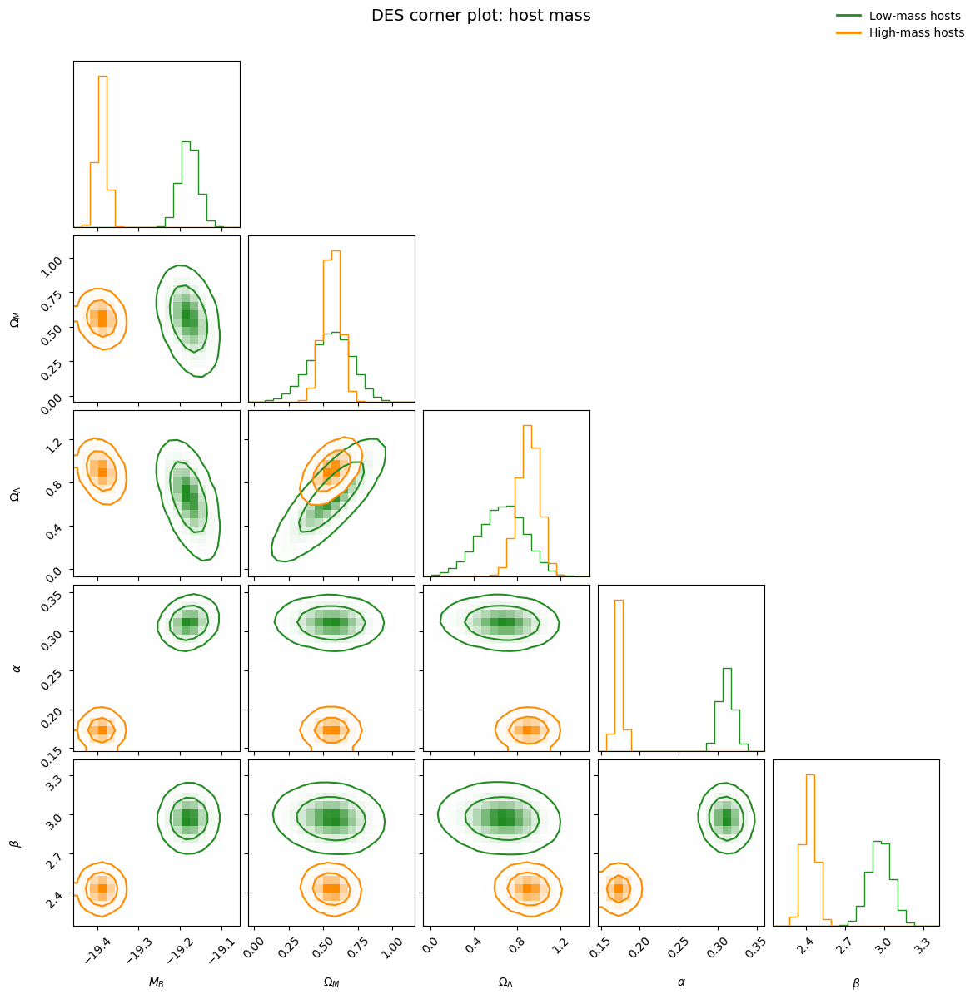

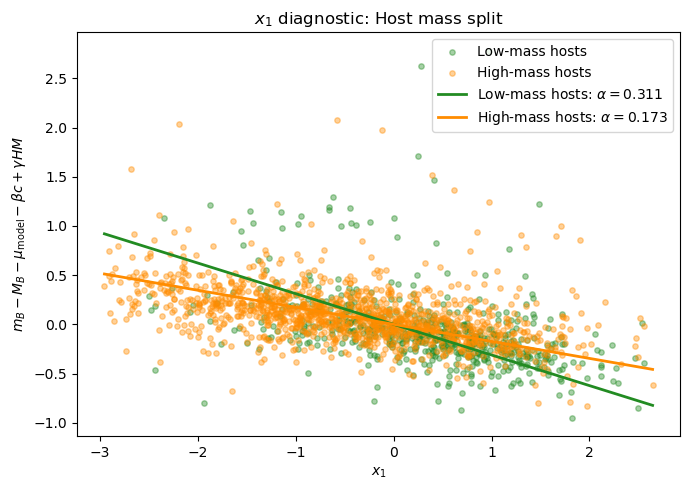

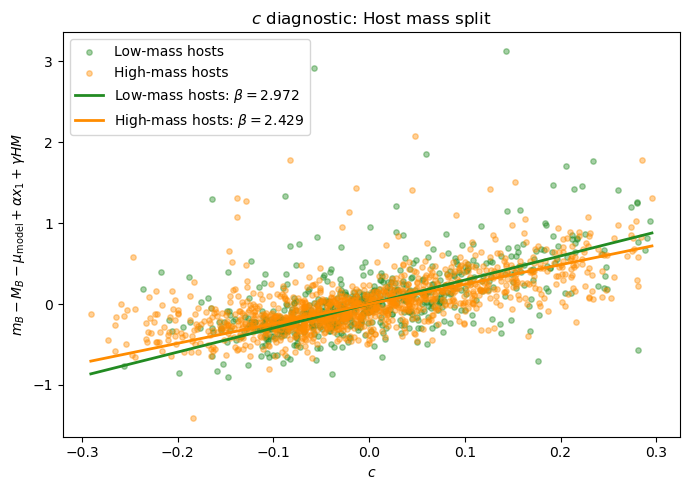

In [20]:
plot_overlaid_corner(
    low_mass_samples_5d,
    high_mass_samples_5d,
    "Low-mass hosts",
    "High-mass hosts",
    "DES corner plot: host mass",
    "forestgreen",
    "darkorange",
    filename=nonclipped_5d_dir / "DES_corner_host_mass_5d.png"
)

plot_mcmc_diagnostics_split(
    low_mass_df_5d,
    low_mass_samples_5d,
    high_mass_df_5d,
    high_mass_samples_5d,
    low_label="Low-mass hosts",
    high_label="High-mass hosts",
    low_color="forestgreen",
    high_color="darkorange",
    title="Host mass split",
    filename_prefix="DES_host_mass",
    clipped=False
)

In [41]:
all_sampler_5d, all_samples_5d = run_mcmc(
    all_data_5d,
    initial_guess_5d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=175
)

all_summary_5d = summarize_samples(
    "All DES supernovae: 5-parameter LambdaCDM",
    all_samples_5d,
    filename=nonclipped_5d_dir / "DES_all_5d.txt"
)

np.save(nonclipped_5d_dir / "DES_all_samples_5d.npy", all_samples_5d)
np.save(nonclipped_5d_dir / "DES_all_sampler_5d.npy", all_sampler_5d)

100%|████████████████████████████████████| 4000/4000 [2:04:41<00:00,  1.87s/it]


All DES supernovae: 5-parameter LambdaCDM
M_B = -19.3614 -0.0101 +0.0101
Omega_M = 0.6520 -0.0544 +0.0530
Omega_Lambda = 1.0348 -0.0820 +0.0793
alpha = 0.1939 -0.0036 +0.0036
beta = 2.7047 -0.0437 +0.0431


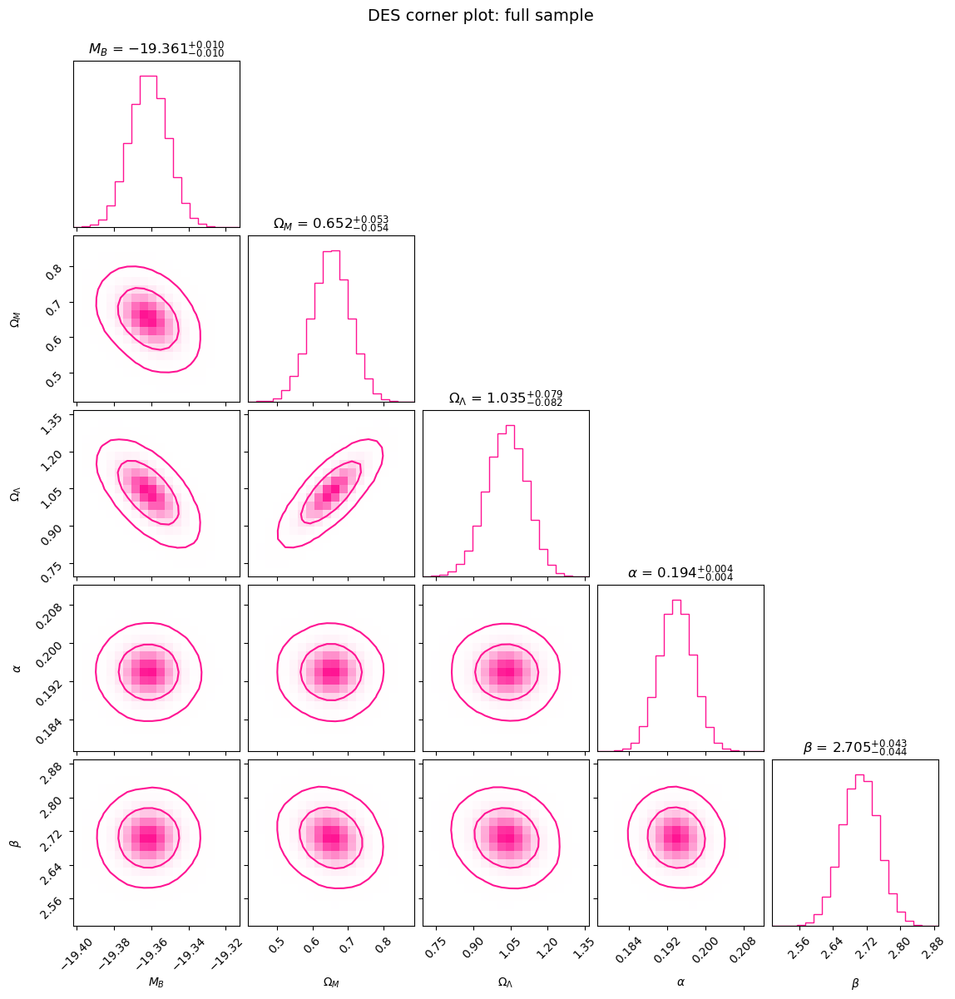

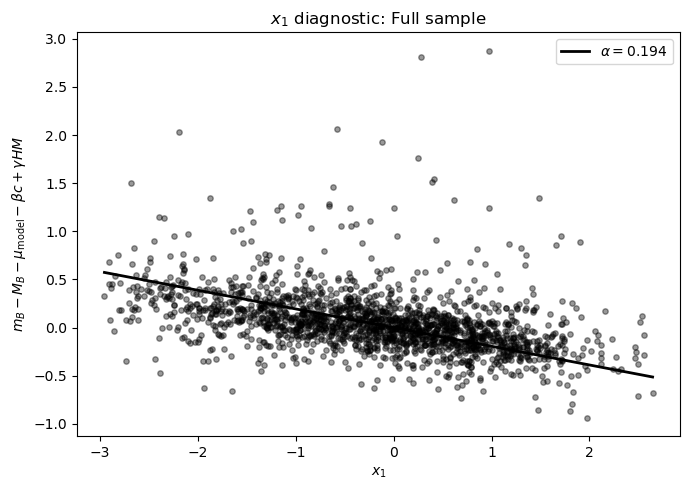

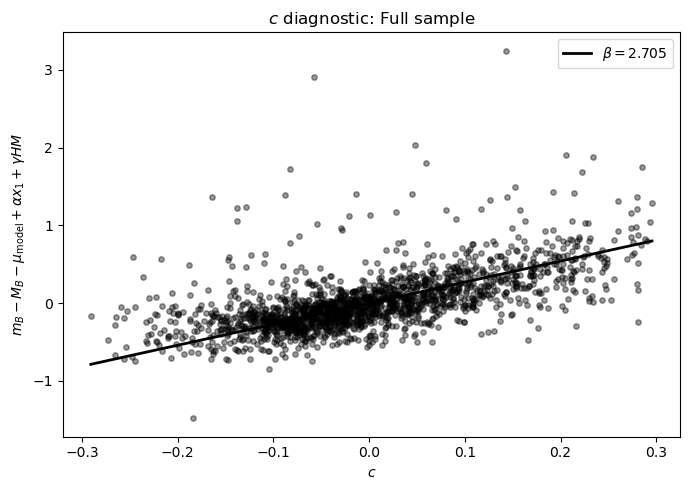

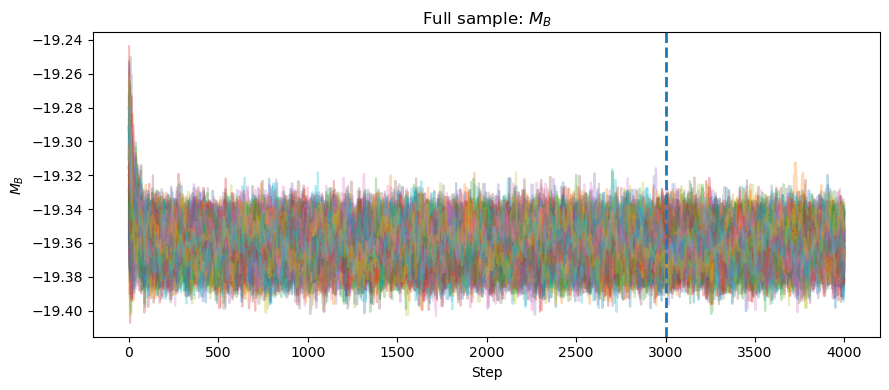

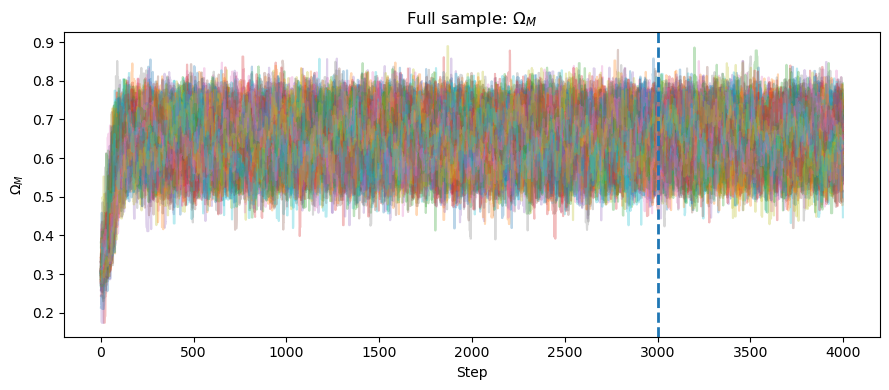

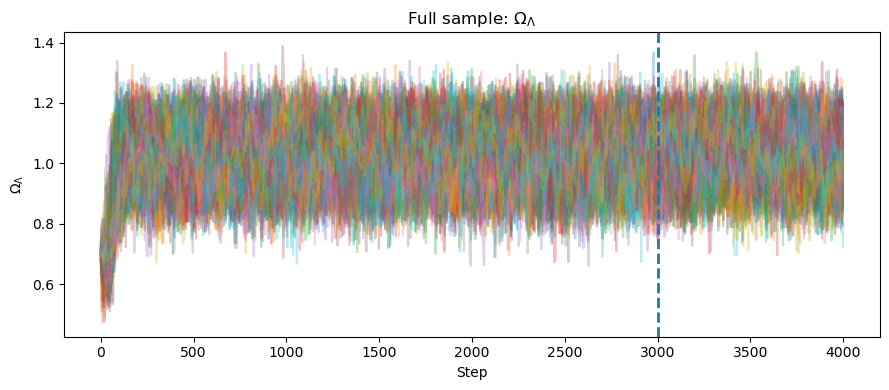

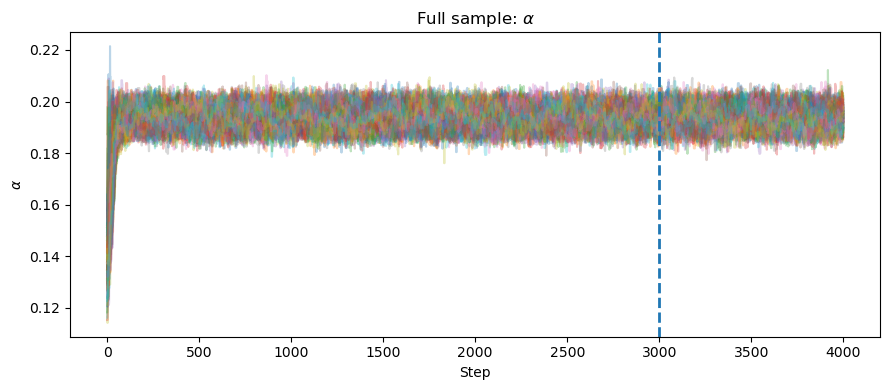

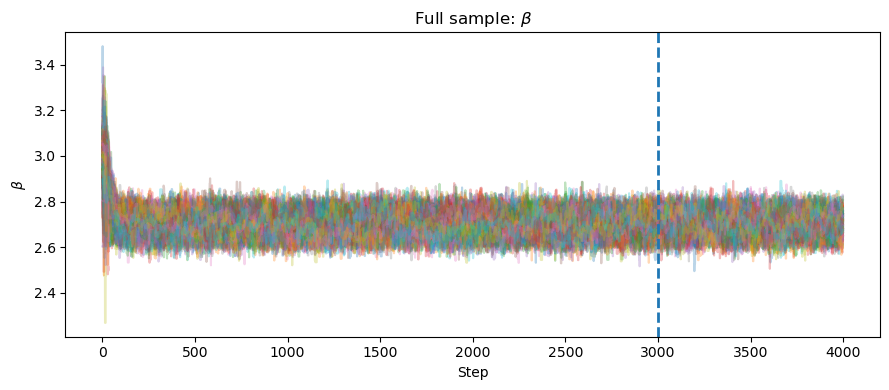

In [42]:
fig = corner.corner(
    all_samples_5d,
    labels=[
        r"$M_B$",
        r"$\Omega_M$",
        r"$\Omega_\Lambda$",
        r"$\alpha$",
        r"$\beta$",
    ],
    levels=(0.683, 0.954),
    color="deeppink",
    plot_datapoints=False,
    plot_density=True,
    fill_contours=False,
    smooth=1.0,
    show_titles=True,
    title_fmt=".3f"
)

fig.suptitle("DES corner plot: full sample", fontsize=14, y=1.02)

fig.savefig(
    nonclipped_5d_dir / "DES_corner_full_sample_5d.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plot_mcmc_diagnostics(
    des_sample_5d,
    all_samples_5d,
    title="Full sample",
    filename_prefix="DES_full_sample",
    clipped=False
)

plot_burnin_diagnostics(
    all_sampler_5d,
    burnin=burnin,
    title="Full sample",
    filename_prefix="DES_full_sample",
    clipped=False
)

## Non-Clipped 6D Fits

Fit $M_B$, $\Omega_M$, $\Omega_\Lambda$, $\alpha$, $\beta$, and $\gamma$, with $H_0$ fixed.

In [23]:
blue_sampler_6d, blue_samples_6d = run_mcmc(
    blue_data_6d,
    initial_guess_6d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=171
)

blue_summary_6d = summarize_samples(
    "Blue hosts: 6-parameter LambdaCDM",
    blue_samples_6d,
    filename=nonclipped_6d_dir / "DES_blue_6d.txt"
)

red_sampler_6d, red_samples_6d = run_mcmc(
    red_data_6d,
    initial_guess_6d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=172
)

red_summary_6d = summarize_samples(
    "Red hosts: 6-parameter LambdaCDM",
    red_samples_6d,
    filename=nonclipped_6d_dir / "DES_red_6d.txt"
)

np.save(nonclipped_6d_dir / "DES_blue_samples_6d.npy", blue_samples_6d)
np.save(nonclipped_6d_dir / "DES_red_samples_6d.npy", red_samples_6d)

100%|████████████████████████████████████| 4000/4000 [1:36:35<00:00,  1.45s/it]



Blue hosts: 6-parameter LambdaCDM
M_B = -19.1919 -0.0189 +0.0192
Omega_M = 0.6225 -0.1037 +0.0987
Omega_Lambda = 0.7929 -0.1574 +0.1437
alpha = 0.2796 -0.0067 +0.0069
beta = 2.7866 -0.0675 +0.0679
gamma = 0.1280 -0.0126 +0.0127


100%|████████████████████████████████████| 4000/4000 [1:33:04<00:00,  1.40s/it]


Red hosts: 6-parameter LambdaCDM
M_B = -19.3911 -0.0217 +0.0212
Omega_M = 0.4979 -0.0837 +0.0786
Omega_Lambda = 0.8004 -0.1234 +0.1166
alpha = 0.1626 -0.0047 +0.0047
beta = 2.3677 -0.0564 +0.0554
gamma = 0.0013 -0.0213 +0.0213


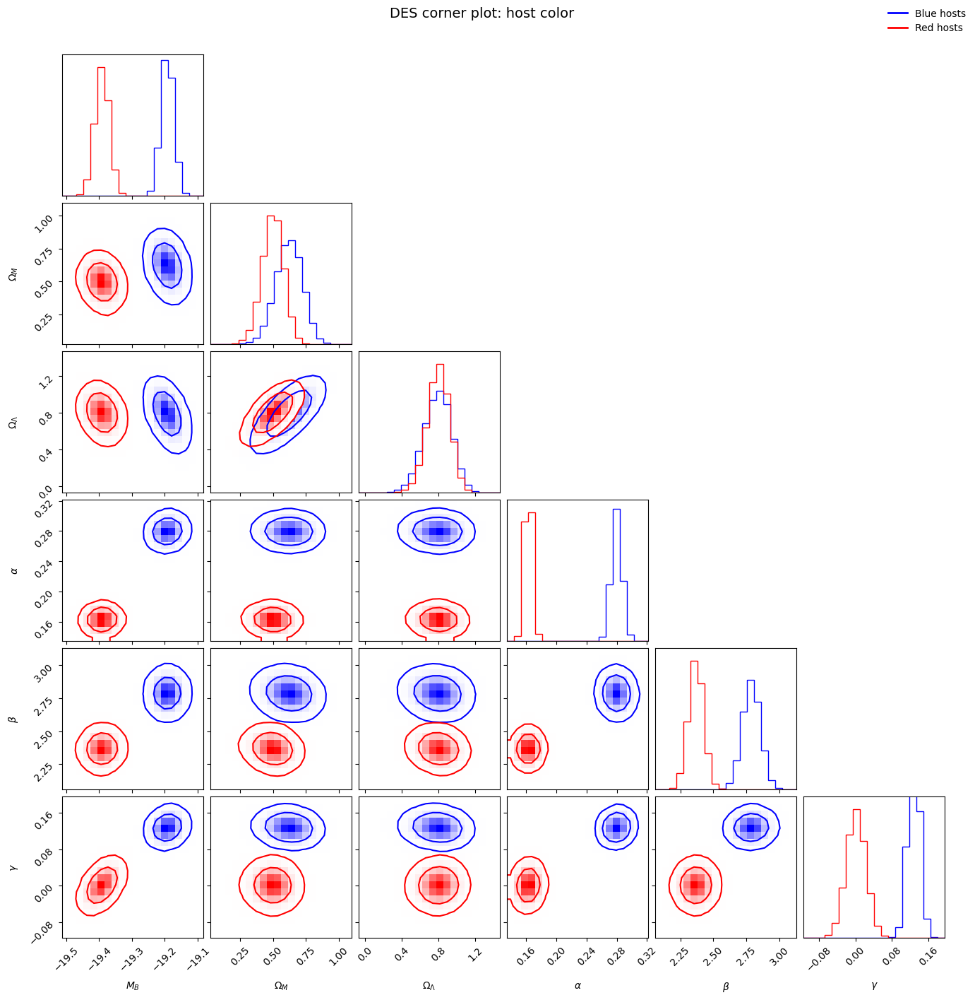

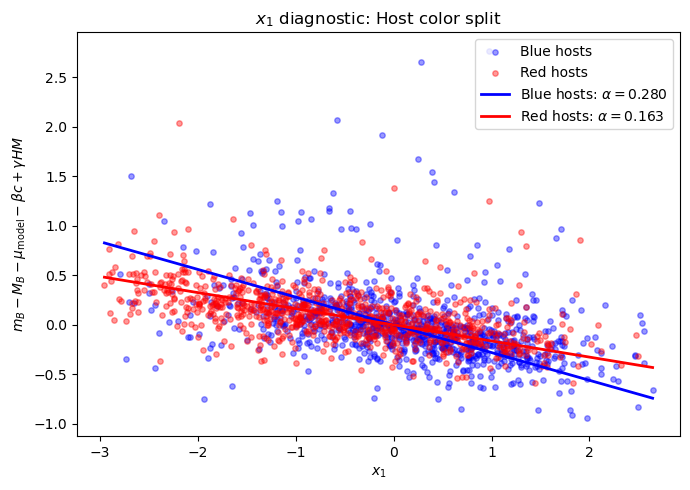

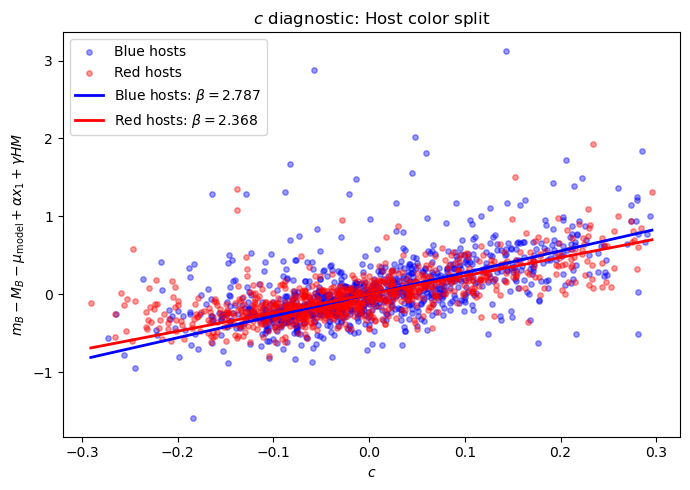

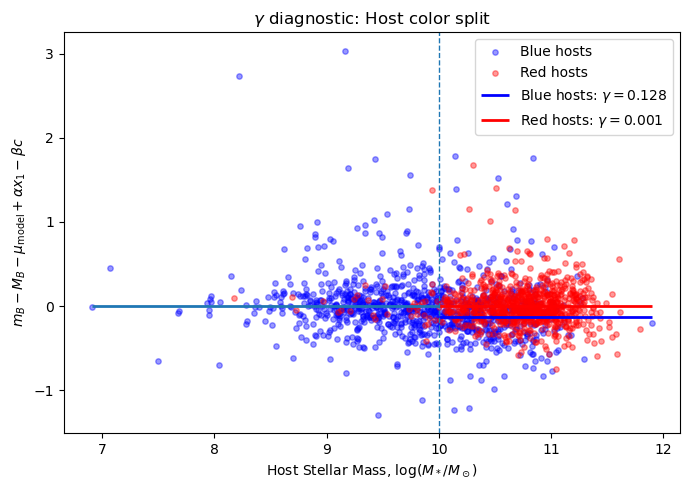

In [24]:
plot_overlaid_corner(
    blue_samples_6d,
    red_samples_6d,
    "Blue hosts",
    "Red hosts",
    "DES corner plot: host color",
    "blue",
    "red",
    filename=nonclipped_6d_dir / "DES_corner_host_color_6d.png"
)

plot_mcmc_diagnostics_split(
    blue_df_6d,
    blue_samples_6d,
    red_df_6d,
    red_samples_6d,
    low_label="Blue hosts",
    high_label="Red hosts",
    low_color="blue",
    high_color="red",
    title="Host color split",
    filename_prefix="DES_host_color",
    clipped=False
)

In [25]:
low_ssfr_sampler_6d, low_ssfr_samples_6d = run_mcmc(
    low_ssfr_data_6d,
    initial_guess_6d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=173
)

low_ssfr_summary_6d = summarize_samples(
    "Low-sSFR hosts: 6-parameter LambdaCDM",
    low_ssfr_samples_6d,
    filename=nonclipped_6d_dir / "DES_low_ssfr_6d.txt"
)

high_ssfr_sampler_6d, high_ssfr_samples_6d = run_mcmc(
    high_ssfr_data_6d,
    initial_guess_6d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=174
)

high_ssfr_summary_6d = summarize_samples(
    "High-sSFR hosts: 6-parameter LambdaCDM",
    high_ssfr_samples_6d,
    filename=nonclipped_6d_dir / "DES_high_ssfr_6d.txt"
)

np.save(nonclipped_6d_dir / "DES_low_ssfr_samples_6d.npy", low_ssfr_samples_6d)
np.save(nonclipped_6d_dir / "DES_high_ssfr_samples_6d.npy", high_ssfr_samples_6d)

100%|████████████████████████████████████| 4000/4000 [1:24:10<00:00,  1.26s/it]



Low-sSFR hosts: 6-parameter LambdaCDM
M_B = -19.3663 -0.0212 +0.0214
Omega_M = 0.4887 -0.0957 +0.0914
Omega_Lambda = 0.7131 -0.1409 +0.1363
alpha = 0.1530 -0.0051 +0.0053
beta = 2.1965 -0.0678 +0.0664
gamma = 0.0193 -0.0226 +0.0228


100%|████████████████████████████████████| 4000/4000 [1:42:45<00:00,  1.54s/it]


High-sSFR hosts: 6-parameter LambdaCDM
M_B = -19.2094 -0.0181 +0.0179
Omega_M = 0.5269 -0.0958 +0.0883
Omega_Lambda = 0.7243 -0.1468 +0.1330
alpha = 0.2600 -0.0056 +0.0056
beta = 2.7764 -0.0586 +0.0585
gamma = 0.1358 -0.0109 +0.0105


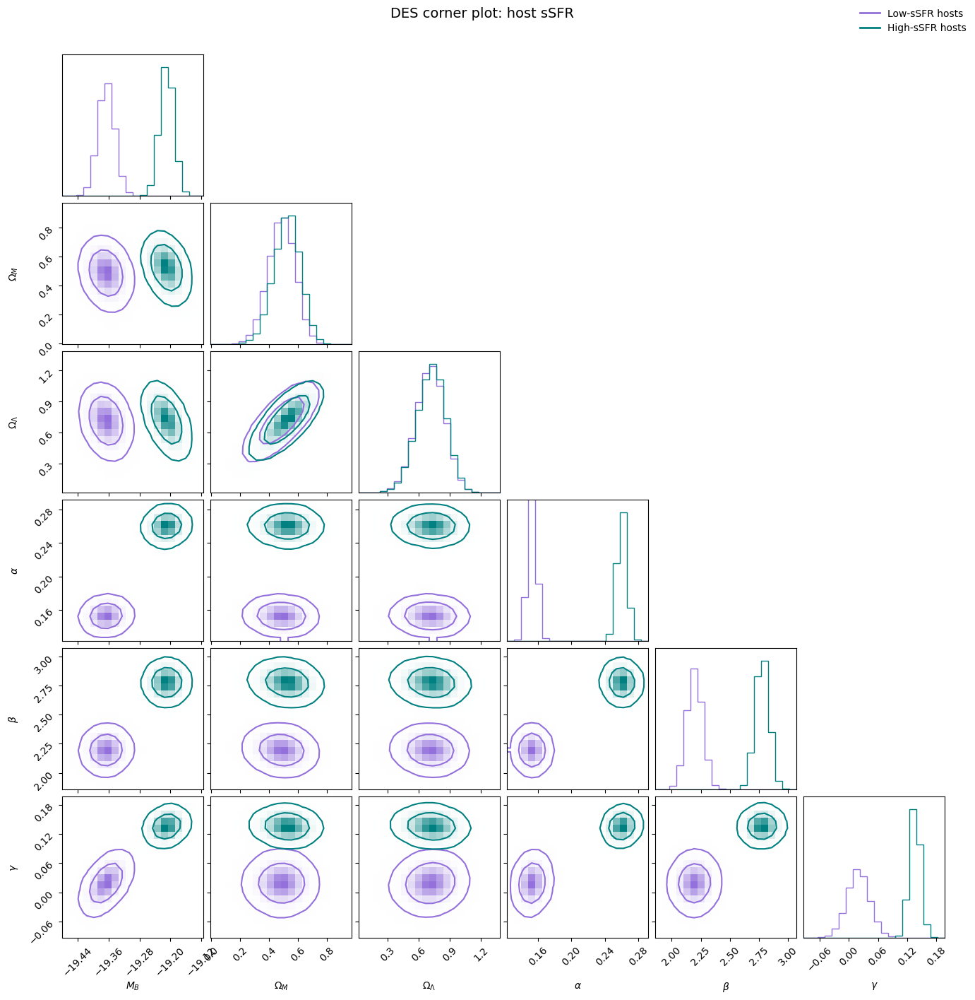

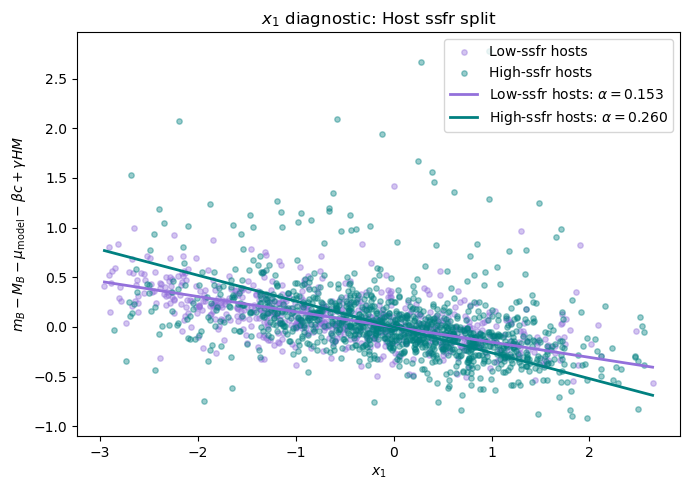

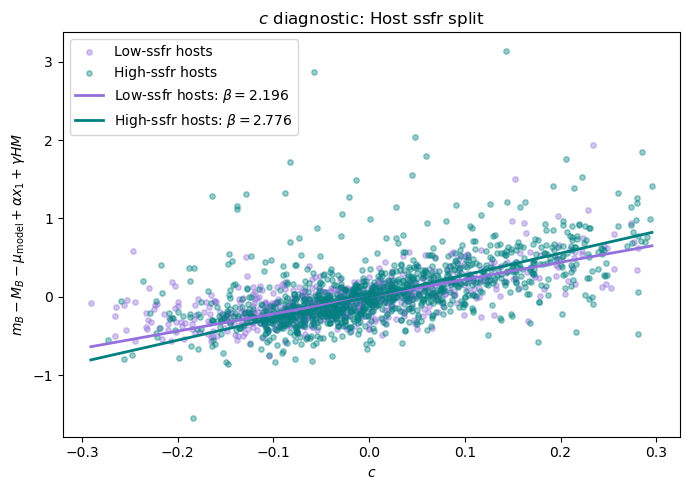

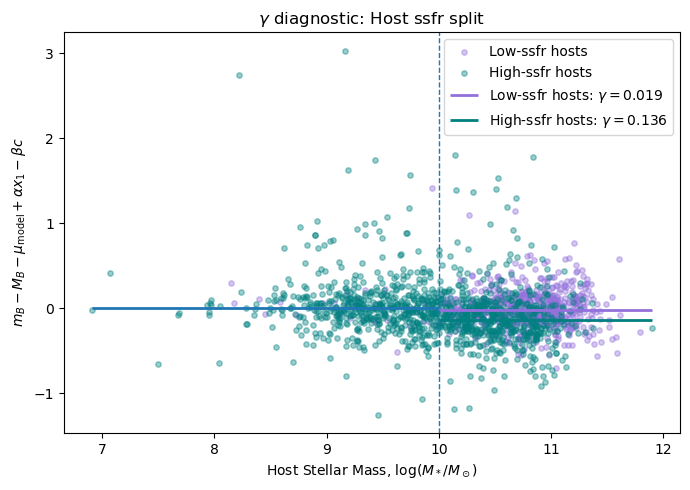

In [26]:
plot_overlaid_corner(
    low_ssfr_samples_6d,
    high_ssfr_samples_6d,
    "Low-sSFR hosts",
    "High-sSFR hosts",
    "DES corner plot: host sSFR",
    "mediumpurple",
    "teal",
    filename=nonclipped_6d_dir / "DES_corner_host_ssfr_6d.png"
)

plot_mcmc_diagnostics_split(
    low_ssfr_df_6d,
    low_ssfr_samples_6d,
    high_ssfr_df_6d,
    high_ssfr_samples_6d,
    low_label="Low-ssfr hosts",
    high_label="High-ssfr hosts",
    low_color="mediumpurple",
    high_color="teal",
    title="Host ssfr split",
    filename_prefix="DES_host_ssfr",
    clipped=False
)

In [43]:
all_sampler_6d, all_samples_6d = run_mcmc(
    all_data_6d,
    initial_guess_6d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=175
)

all_summary_6d = summarize_samples(
    "All DES supernovae: 6-parameter LambdaCDM",
    all_samples_6d,
    filename=nonclipped_6d_dir / "DES_all_6d.txt"
)

np.save(nonclipped_6d_dir / "DES_all_samples_6d.npy", all_samples_6d)
np.save(nonclipped_6d_dir / "DES_all_sampler_6d.npy", all_sampler_6d)

100%|████████████████████████████████████| 4000/4000 [2:05:17<00:00,  1.88s/it]



All DES supernovae: 6-parameter LambdaCDM
M_B = -19.2618 -0.0123 +0.0123
Omega_M = 0.5282 -0.0651 +0.0599
Omega_Lambda = 0.8451 -0.0954 +0.0894
alpha = 0.2117 -0.0038 +0.0037
beta = 2.6733 -0.0430 +0.0445
gamma = 0.1391 -0.0084 +0.0083


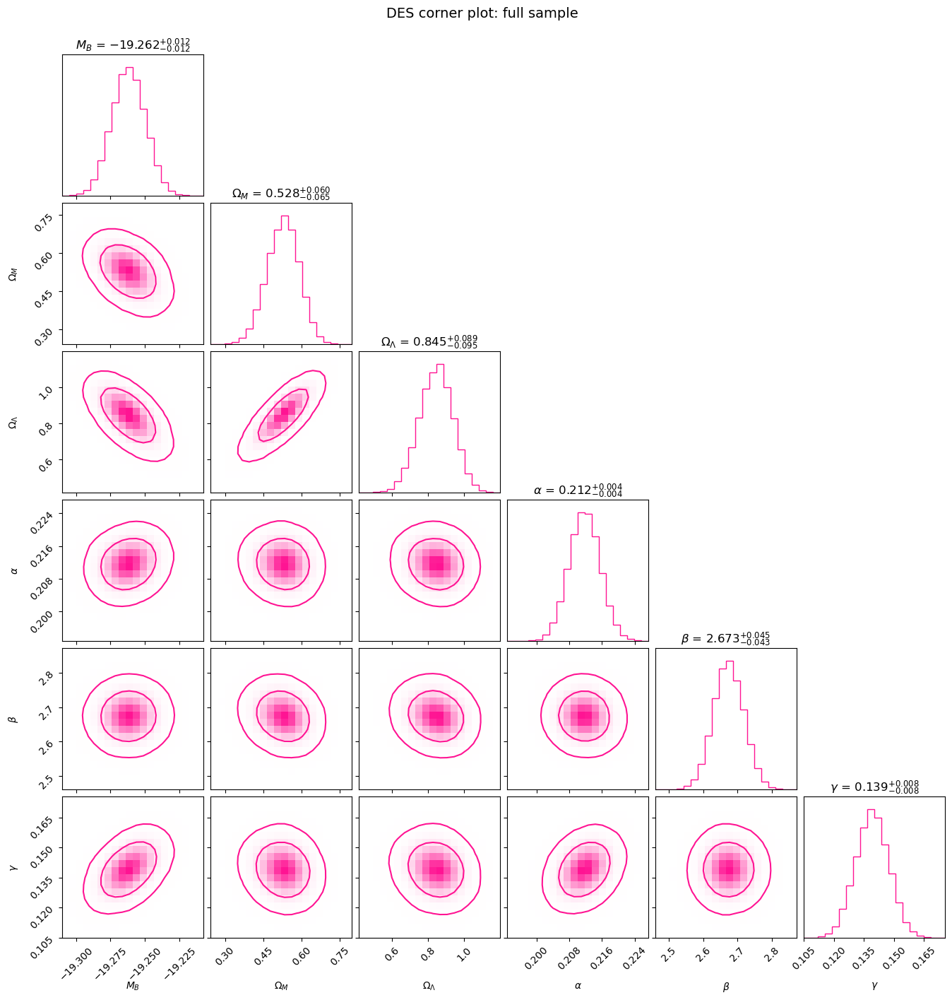

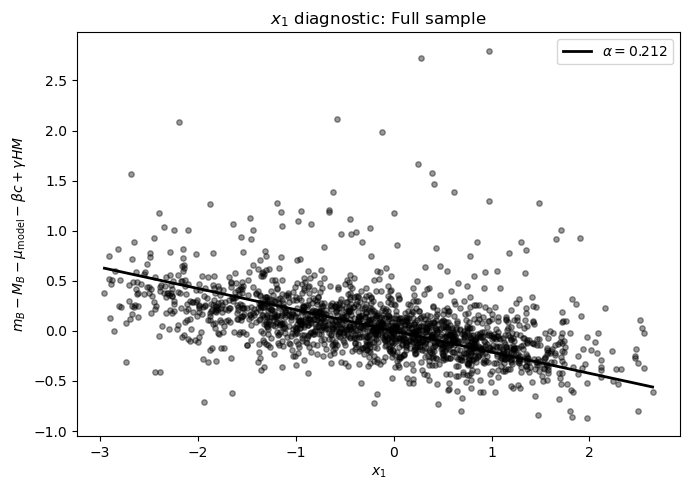

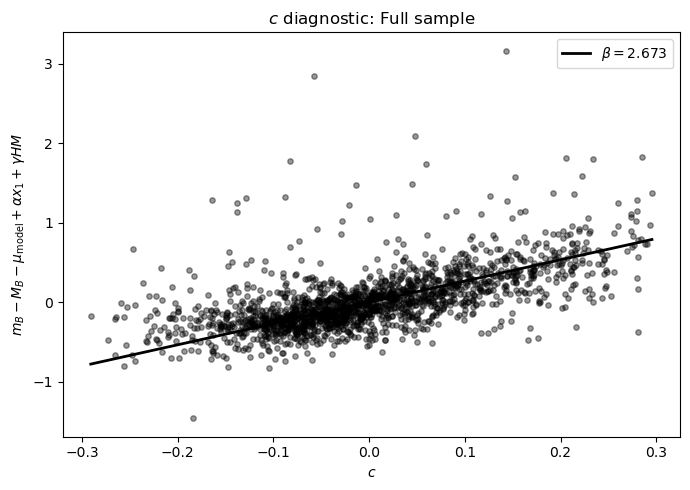

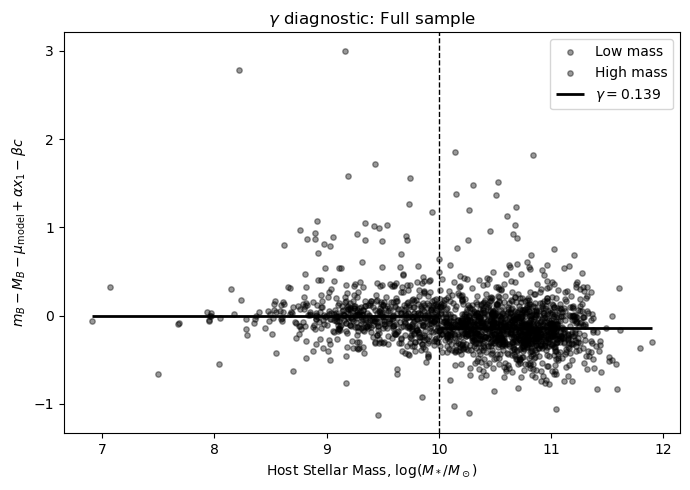

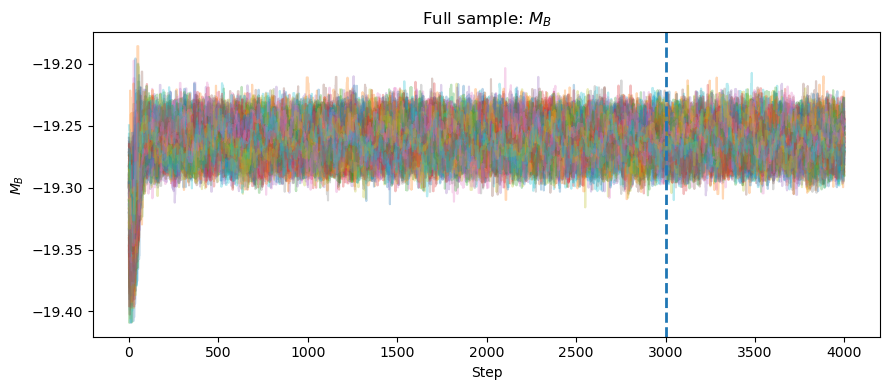

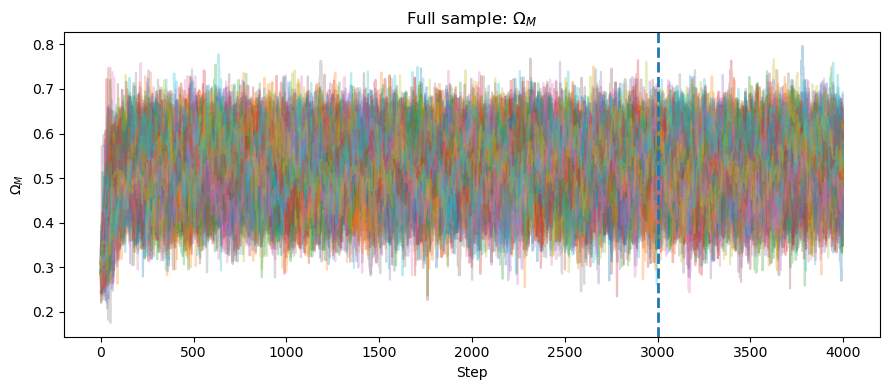

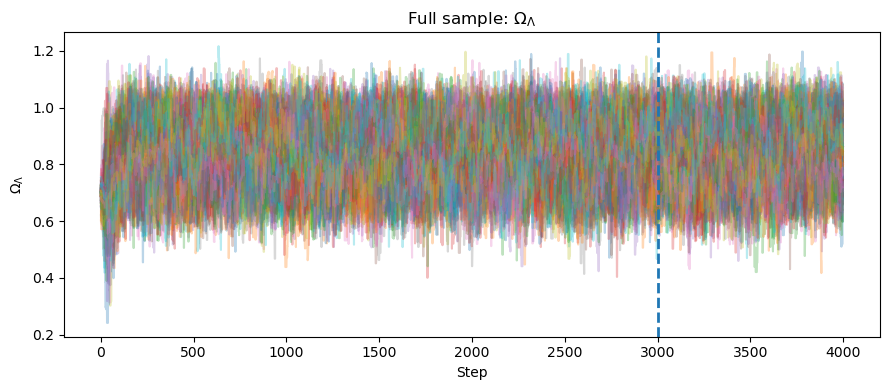

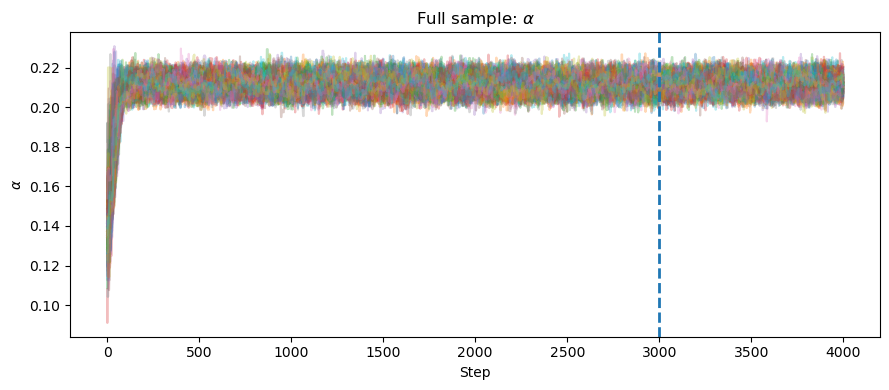

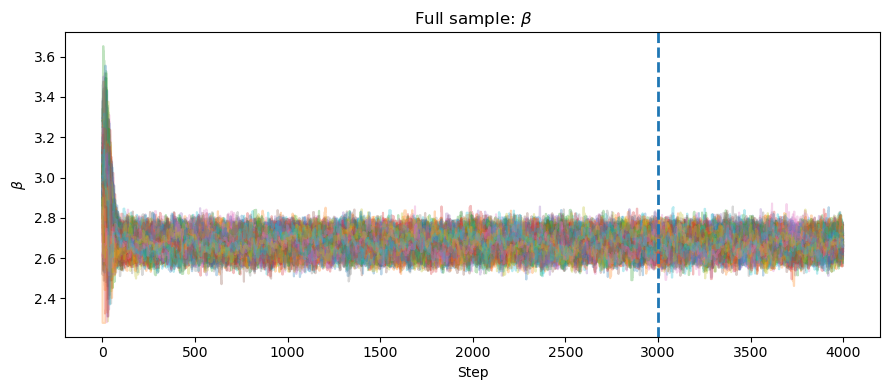

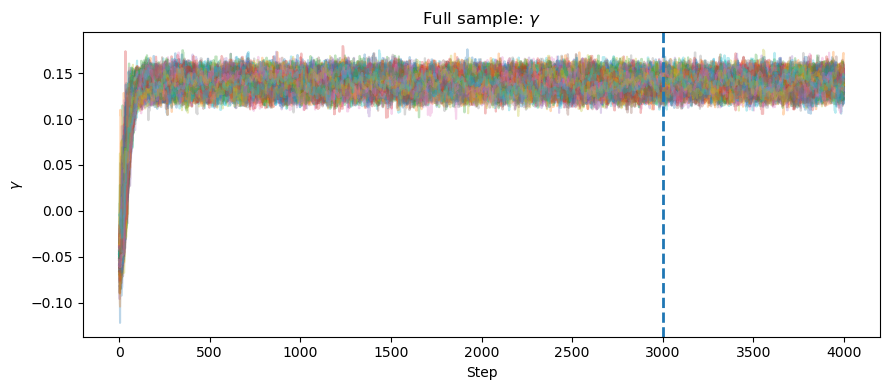

In [44]:
fig = corner.corner(
    all_samples_6d,
    labels=[
        r"$M_B$",
        r"$\Omega_M$",
        r"$\Omega_\Lambda$",
        r"$\alpha$",
        r"$\beta$",
        r"$\gamma$"
    ],
    levels=(0.683, 0.954),
    color="deeppink",
    plot_datapoints=False,
    plot_density=True,
    fill_contours=False,
    smooth=1.0,
    show_titles=True,
    title_fmt=".3f"
)

fig.suptitle("DES corner plot: full sample", fontsize=14, y=1.02)

fig.savefig(
    nonclipped_6d_dir / "DES_corner_full_sample_6d.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plot_mcmc_diagnostics(
    des_sample_6d,
    all_samples_6d,
    title="Full sample",
    filename_prefix="DES_full_sample",
    clipped=False
)

plot_burnin_diagnostics(
    all_sampler_6d,
    burnin=burnin,
    title="Full sample",
    filename_prefix="DES_full_sample",
    clipped=False
)

# 2.5-Sigma Clipping

- **5D:** uses the median `all_samples_5d` values of $M_B$, $\Omega_M$, $\Omega_\Lambda$, $\alpha$, $\beta$.
- **6D:** uses the median `all_samples_6d` values of $M_B$, $\Omega_M$, $\Omega_\Lambda$, $\alpha$, $\beta$, and $\gamma$.

In [35]:
# =====================================================
# 5D clipping from the non-clipped 5D fit
# Parameters: M_B, Omega_M, Omega_Lambda, alpha, beta
# H0 is fixed at H_0
# =====================================================

M_B_clip_5d = np.median(all_samples_5d[:, 0])
Omega_M_clip_5d = np.median(all_samples_5d[:, 1])
Omega_Lambda_clip_5d = np.median(all_samples_5d[:, 2])
alpha_clip_5d = np.median(all_samples_5d[:, 3])
beta_clip_5d = np.median(all_samples_5d[:, 4])

cosmology_clip_5d = LambdaCDM(
    H0=H_0,
    Om0=Omega_M_clip_5d,
    Ode0=Omega_Lambda_clip_5d
)

des_sample_clipped_5d = des_sample_5d.copy()
des_sample_clipped_5d["MU_OBS"] = (
    des_sample_clipped_5d["mB"]
    - M_B_clip_5d
    + alpha_clip_5d * des_sample_clipped_5d["x1"]
    - beta_clip_5d * des_sample_clipped_5d["c"]
)

des_sample_clipped_5d["MU_PRED"] = cosmology_clip_5d.distmod(des_sample_clipped_5d["zHD"].to_numpy()).value
des_sample_clipped_5d["RESIDUAL"] = des_sample_clipped_5d["MU_OBS"] - des_sample_clipped_5d["MU_PRED"]

des_sample_clipped_5d["VARIANCE"] = (
    des_sample_clipped_5d["mBERR"]**2
    + alpha_clip_5d**2 * des_sample_clipped_5d["x1ERR"]**2
    + beta_clip_5d**2 * des_sample_clipped_5d["cERR"]**2
    + 2.0 * alpha_clip_5d * des_sample_clipped_5d["COV_mB_x1"]
    - 2.0 * beta_clip_5d * des_sample_clipped_5d["COV_mB_c"]
    - 2.0 * alpha_clip_5d * beta_clip_5d * des_sample_clipped_5d["COV_x1_c"]
    + des_sample_clipped_5d["MUERR_VPEC"]**2
    + des_sample_clipped_5d["LENSDMUERR"]**2
    + sigma_int**2
)

des_sample_clipped_5d["SIGMA_TOTAL"] = np.sqrt(des_sample_clipped_5d["VARIANCE"])
des_sample_clipped_5d["SIGMA_RESIDUAL"] = des_sample_clipped_5d["RESIDUAL"] / des_sample_clipped_5d["SIGMA_TOTAL"]

outliers_5d = des_sample_clipped_5d[np.abs(des_sample_clipped_5d["SIGMA_RESIDUAL"]) > sigma_cut].copy()
des_sample_clipped_5d = des_sample_clipped_5d[np.abs(des_sample_clipped_5d["SIGMA_RESIDUAL"]) <= sigma_cut].copy()


# =====================================================
# 6D clipping from the non-clipped 6D fit
# Parameters: M_B, Omega_M, Omega_Lambda, alpha, beta, gamma
# H0 is fixed at H_0
# =====================================================

M_B_clip_6d = np.median(all_samples_6d[:, 0])
Omega_M_clip_6d = np.median(all_samples_6d[:, 1])
Omega_Lambda_clip_6d = np.median(all_samples_6d[:, 2])
alpha_clip_6d = np.median(all_samples_6d[:, 3])
beta_clip_6d = np.median(all_samples_6d[:, 4])
gamma_clip_6d = np.median(all_samples_6d[:, 5])

cosmology_clip_6d = LambdaCDM(
    H0=H_0,
    Om0=Omega_M_clip_6d,
    Ode0=Omega_Lambda_clip_6d
)

des_sample_clipped_6d = des_sample_6d.copy()
HM_clip_6d = (des_sample_clipped_6d["HOST_LOGMASS"] >= mass_cut).astype(float)

des_sample_clipped_6d["MU_OBS"] = (
    des_sample_clipped_6d["mB"]
    - M_B_clip_6d
    + alpha_clip_6d * des_sample_clipped_6d["x1"]
    - beta_clip_6d * des_sample_clipped_6d["c"]
    + gamma_clip_6d * HM_clip_6d
)

des_sample_clipped_6d["MU_PRED"] = cosmology_clip_6d.distmod(des_sample_clipped_6d["zHD"].to_numpy()).value
des_sample_clipped_6d["RESIDUAL"] = des_sample_clipped_6d["MU_OBS"] - des_sample_clipped_6d["MU_PRED"]

des_sample_clipped_6d["VARIANCE"] = (
    des_sample_clipped_6d["mBERR"]**2
    + alpha_clip_6d**2 * des_sample_clipped_6d["x1ERR"]**2
    + beta_clip_6d**2 * des_sample_clipped_6d["cERR"]**2
    + 2.0 * alpha_clip_6d * des_sample_clipped_6d["COV_mB_x1"]
    - 2.0 * beta_clip_6d * des_sample_clipped_6d["COV_mB_c"]
    - 2.0 * alpha_clip_6d * beta_clip_6d * des_sample_clipped_6d["COV_x1_c"]
    + des_sample_clipped_6d["MUERR_VPEC"]**2
    + des_sample_clipped_6d["LENSDMUERR"]**2
    + sigma_int**2
)

des_sample_clipped_6d["SIGMA_TOTAL"] = np.sqrt(des_sample_clipped_6d["VARIANCE"])
des_sample_clipped_6d["SIGMA_RESIDUAL"] = des_sample_clipped_6d["RESIDUAL"] / des_sample_clipped_6d["SIGMA_TOTAL"]

outliers_6d = des_sample_clipped_6d[np.abs(des_sample_clipped_6d["SIGMA_RESIDUAL"]) > sigma_cut].copy()
des_sample_clipped_6d = des_sample_clipped_6d[np.abs(des_sample_clipped_6d["SIGMA_RESIDUAL"]) <= sigma_cut].copy()

print(f"5D: {len(des_sample_5d)} -> {len(des_sample_clipped_5d)} ({len(outliers_5d)} removed)")
print(f"6D: {len(des_sample_6d)} -> {len(des_sample_clipped_6d)} ({len(outliers_6d)} removed)")

5D: 1810 -> 1695 (115 removed)
6D: 1810 -> 1710 (100 removed)


In [36]:
# =====================================================
# 5D clipped splits and tuples
# =====================================================

clipped_low_mass_df_5d = des_sample_clipped_5d[des_sample_clipped_5d["HOST_LOGMASS"] < mass_cut].copy()
clipped_high_mass_df_5d = des_sample_clipped_5d[des_sample_clipped_5d["HOST_LOGMASS"] >= mass_cut].copy()

clipped_all_data_5d = make_data_tuple(des_sample_clipped_5d, nparam=5)
clipped_low_mass_data_5d = make_data_tuple(clipped_low_mass_df_5d, nparam=5)
clipped_high_mass_data_5d = make_data_tuple(clipped_high_mass_df_5d, nparam=5)


# =====================================================
# 6D clipped splits and tuples
# =====================================================

clipped_blue_df_6d = des_sample_clipped_6d[des_sample_clipped_6d["HOST_COLOR"] < color_cut].copy()
clipped_red_df_6d = des_sample_clipped_6d[des_sample_clipped_6d["HOST_COLOR"] >= color_cut].copy()
clipped_low_ssfr_df_6d = des_sample_clipped_6d[des_sample_clipped_6d["HOST_LOGsSFR"] < ssfr_cut].copy()
clipped_high_ssfr_df_6d = des_sample_clipped_6d[des_sample_clipped_6d["HOST_LOGsSFR"] >= ssfr_cut].copy()

clipped_all_data_6d = make_data_tuple(des_sample_clipped_6d, nparam=6)
clipped_blue_data_6d = make_data_tuple(clipped_blue_df_6d, nparam=6)
clipped_red_data_6d = make_data_tuple(clipped_red_df_6d, nparam=6)
clipped_low_ssfr_data_6d = make_data_tuple(clipped_low_ssfr_df_6d, nparam=6)
clipped_high_ssfr_data_6d = make_data_tuple(clipped_high_ssfr_df_6d, nparam=6)

## Clipped 5D Fits

In [31]:
clipped_low_mass_sampler_5d, clipped_low_mass_samples_5d = run_mcmc(
    clipped_low_mass_data_5d,
    initial_guess_5d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=151
)

clipped_low_mass_summary_5d = summarize_samples(
    "Low-mass hosts: clipped 5-parameter LambdaCDM",
    clipped_low_mass_samples_5d,
    filename=clipped_5d_dir / "DES_low_mass_5d_clipped.txt"
)

clipped_high_mass_sampler_5d, clipped_high_mass_samples_5d = run_mcmc(
    clipped_high_mass_data_5d,
    initial_guess_5d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=152
)

clipped_high_mass_summary_5d = summarize_samples(
    "High-mass hosts: clipped 5-parameter LambdaCDM",
    clipped_high_mass_samples_5d,
    filename=clipped_5d_dir / "DES_high_mass_5d_clipped.txt"
)

np.save(clipped_5d_dir / "DES_clipped_low_mass_samples_5d.npy", clipped_low_mass_samples_5d)
np.save(clipped_5d_dir / "DES_clipped_high_mass_samples_5d.npy", clipped_high_mass_samples_5d)

100%|████████████████████████████████████| 4000/4000 [1:18:15<00:00,  1.17s/it]



Low-mass hosts: clipped 5-parameter LambdaCDM
M_B = -19.3445 -0.0193 +0.0197
Omega_M = 0.5603 -0.1098 +0.1003
Omega_Lambda = 0.9722 -0.1580 +0.1479
alpha = 0.1585 -0.0074 +0.0073
beta = 2.5662 -0.0671 +0.0687


100%|████████████████████████████████████| 4000/4000 [1:37:40<00:00,  1.47s/it]


High-mass hosts: clipped 5-parameter LambdaCDM
M_B = -19.3800 -0.0125 +0.0126
Omega_M = 0.5425 -0.0655 +0.0622
Omega_Lambda = 0.8787 -0.1010 +0.0964
alpha = 0.1437 -0.0040 +0.0041
beta = 2.3289 -0.0438 +0.0450


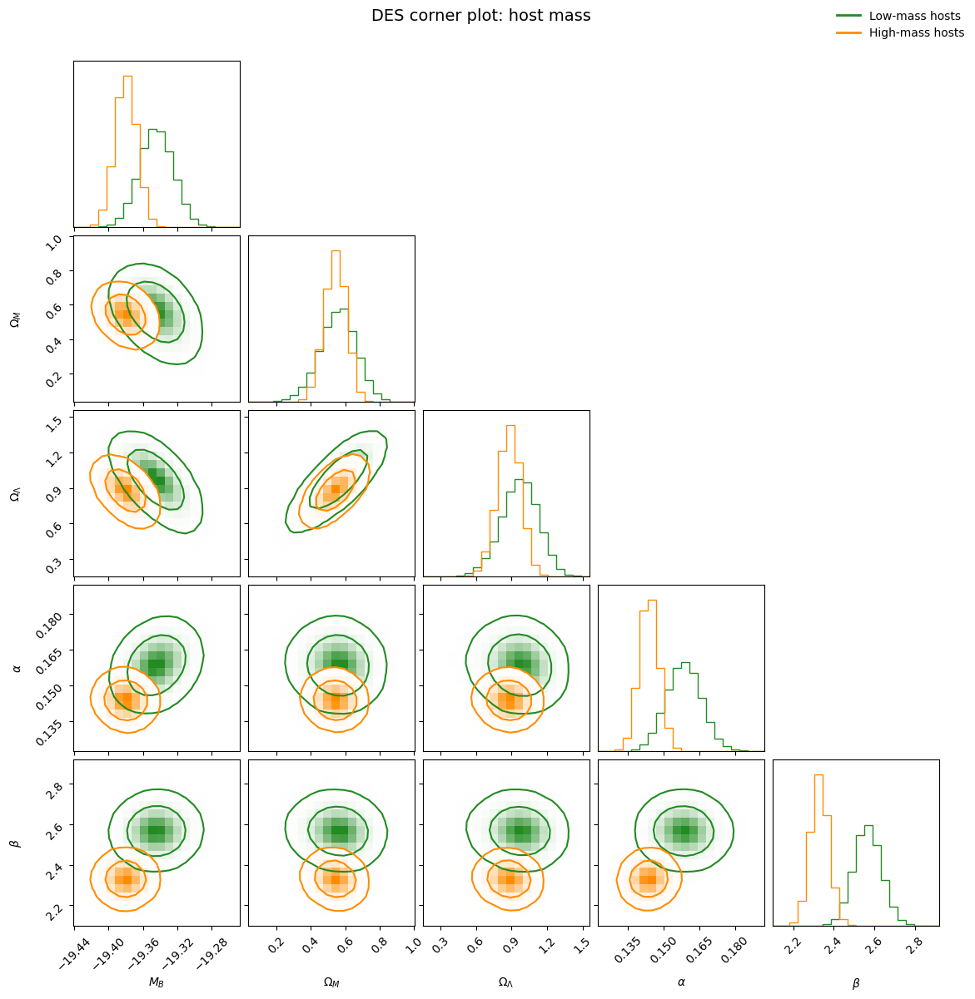

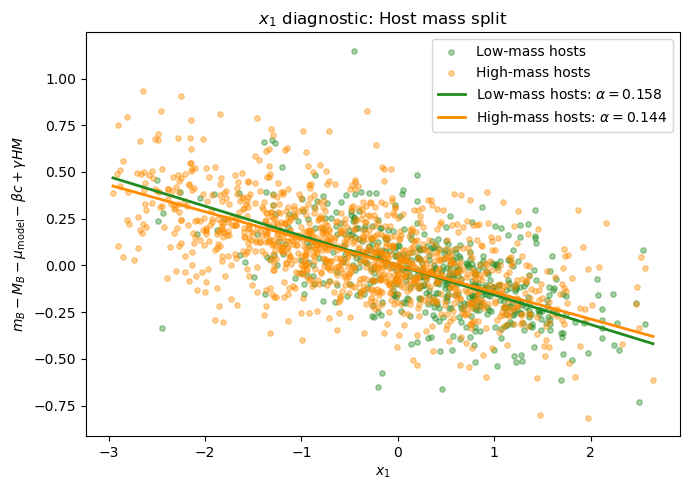

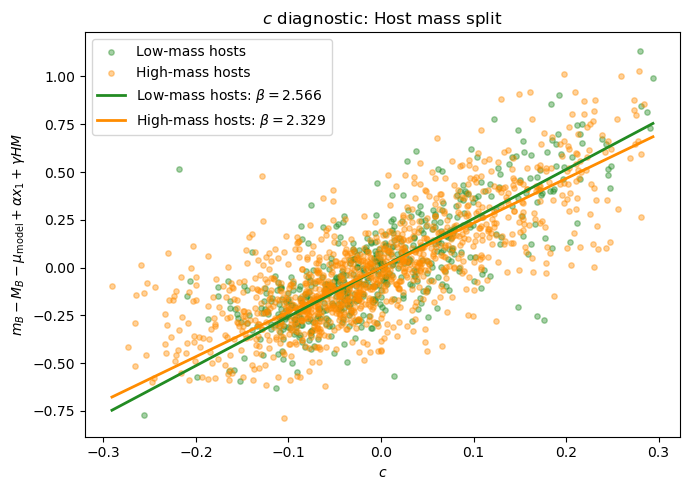

In [32]:
plot_overlaid_corner(
    clipped_low_mass_samples_5d,
    clipped_high_mass_samples_5d,
    "Low-mass hosts",
    "High-mass hosts",
    "DES corner plot: host mass",
    "forestgreen",
    "darkorange",
    filename=clipped_5d_dir / "DES_clipped_corner_host_mass_5d.png"
)

plot_mcmc_diagnostics_split(
    clipped_low_mass_df_5d,
    clipped_low_mass_samples_5d,
    clipped_high_mass_df_5d,
    clipped_high_mass_samples_5d,
    low_label="Low-mass hosts",
    high_label="High-mass hosts",
    low_color="forestgreen",
    high_color="darkorange",
    title="Host mass split",
    filename_prefix="DES_host_mass",
    clipped=True
)

In [47]:
clipped_all_sampler_5d, clipped_all_samples_5d = run_mcmc(
    clipped_all_data_5d,
    initial_guess_5d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=156
)

clipped_all_summary_5d = summarize_samples(
    "All DES supernovae: clipped 5-parameter LambdaCDM",
    clipped_all_samples_5d,
    filename=clipped_5d_dir / "DES_clipped_all_5d.txt"
)

np.save(clipped_5d_dir / "DES_clipped_all_samples_5d.npy", clipped_all_samples_5d)

100%|████████████████████████████████████| 4000/4000 [1:59:46<00:00,  1.80s/it]


All DES supernovae: clipped 5-parameter LambdaCDM
M_B = -19.3752 -0.0099 +0.0101
Omega_M = 0.5896 -0.0526 +0.0503
Omega_Lambda = 0.9798 -0.0803 +0.0774
alpha = 0.1405 -0.0033 +0.0033
beta = 2.4016 -0.0372 +0.0378


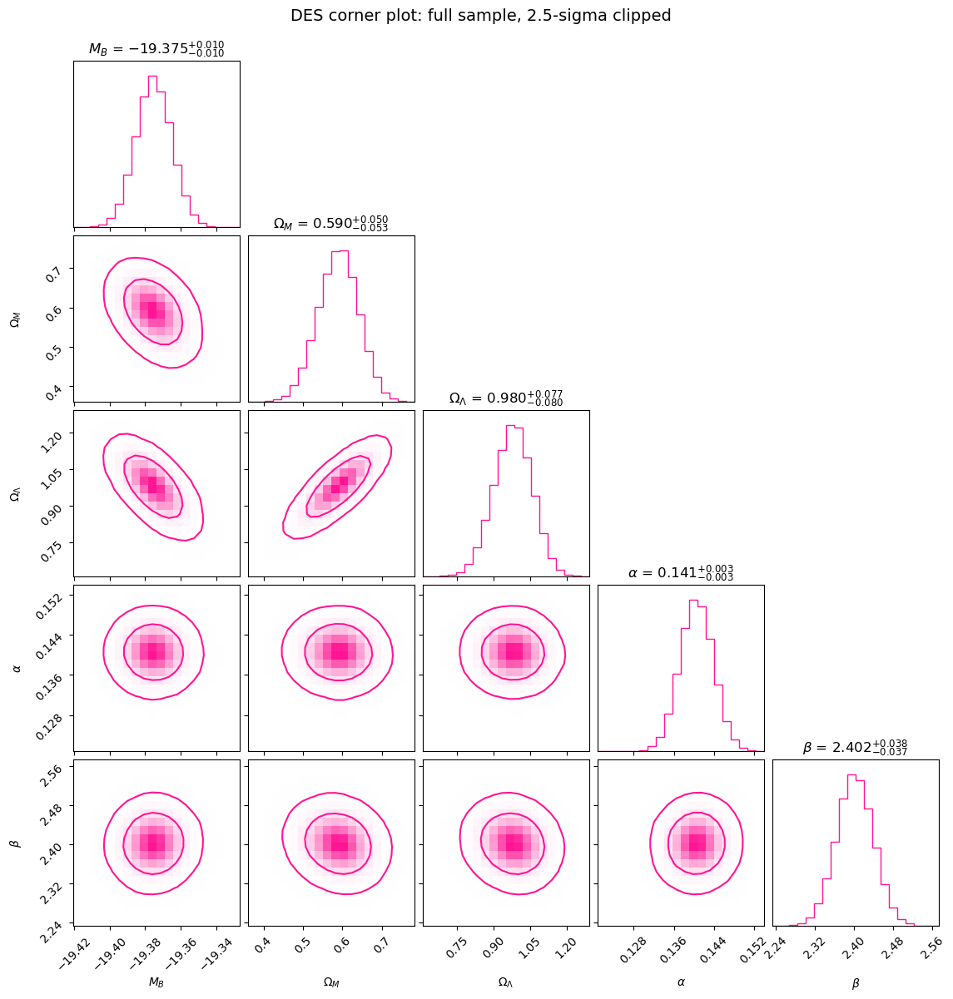

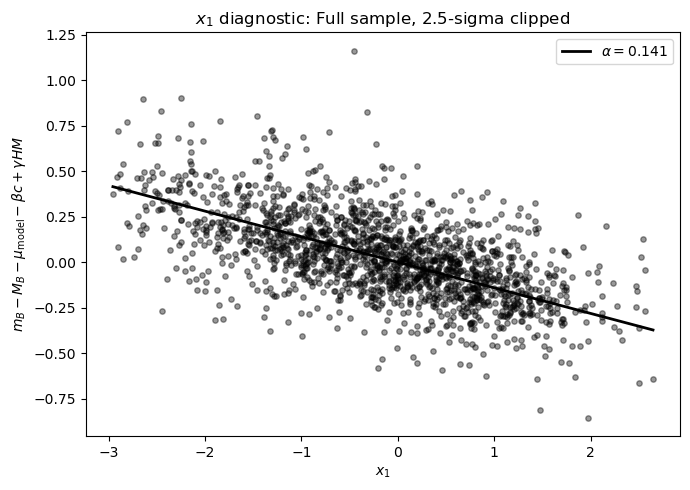

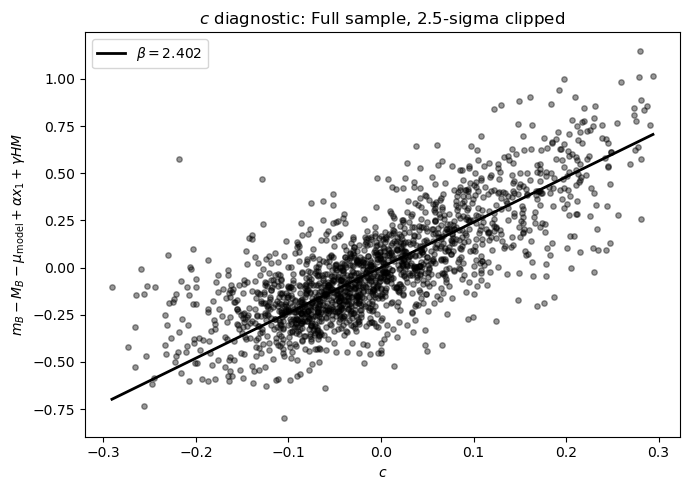

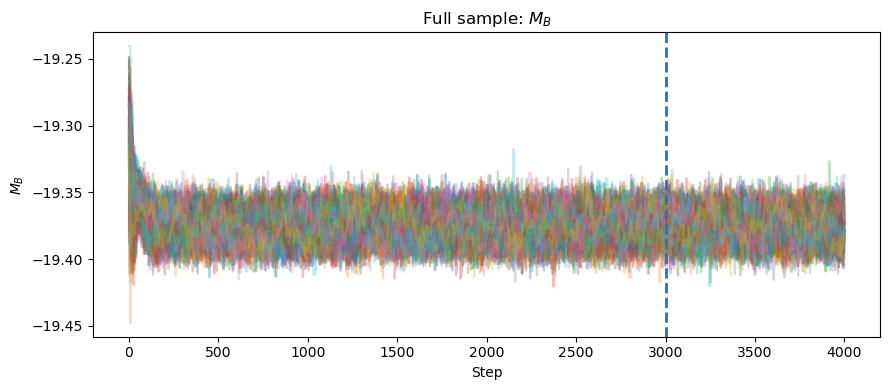

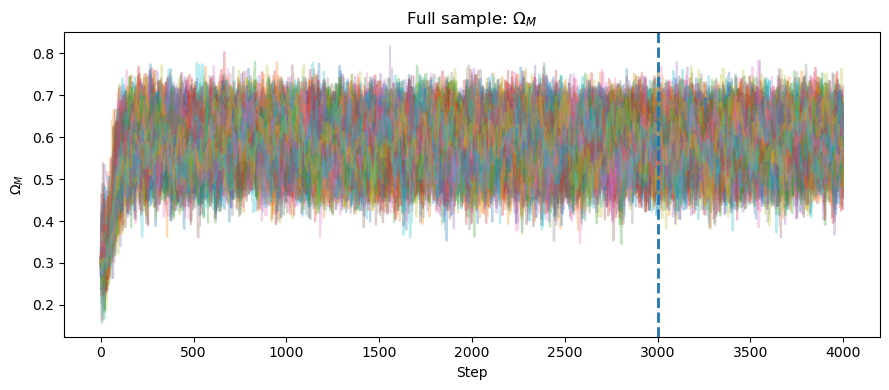

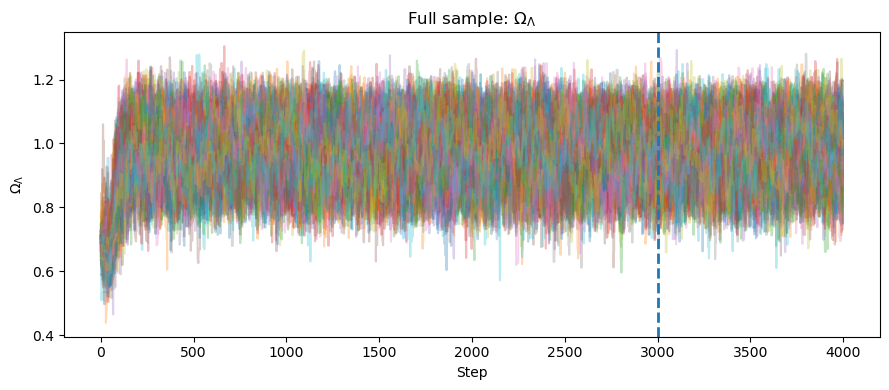

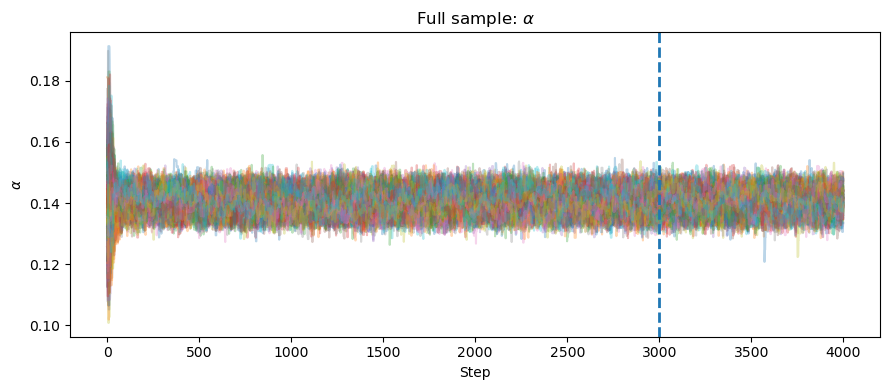

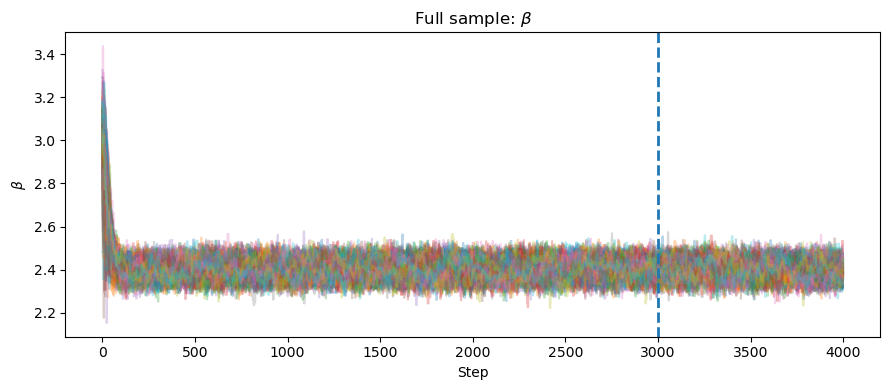

In [48]:
fig = corner.corner(
    clipped_all_samples_5d,
    labels=[
        r"$M_B$",
        r"$\Omega_M$",
        r"$\Omega_\Lambda$",
        r"$\alpha$",
        r"$\beta$",
    ],
    levels=(0.683, 0.954),
    color="deeppink",
    plot_datapoints=False,
    plot_density=True,
    fill_contours=False,
    smooth=1.0,
    show_titles=True,
    title_fmt=".3f"
)

fig.suptitle("DES corner plot: full sample, 2.5-sigma clipped", fontsize=14, y=1.02)

fig.savefig(
    clipped_5d_dir / "DES_clipped_corner_full_sample_5d.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plot_mcmc_diagnostics(
    des_sample_clipped_5d,
    clipped_all_samples_5d,
    title="Full sample, 2.5-sigma clipped",
    filename_prefix="DES_full_sample",
    clipped=True
)

plot_burnin_diagnostics(
    clipped_all_sampler_5d,
    burnin=burnin,
    title="Full sample",
    filename_prefix="DES_full_sample",
    clipped=True
)

## Clipped 6D Fits

In [35]:
clipped_blue_sampler_6d, clipped_blue_samples_6d = run_mcmc(
    clipped_blue_data_6d,
    initial_guess_6d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=171
)

clipped_blue_summary_6d = summarize_samples(
    "Blue hosts: clipped 6-parameter LambdaCDM",
    clipped_blue_samples_6d,
    filename=clipped_6d_dir / "DES_blue_6d_clipped.txt"
)

clipped_red_sampler_6d, clipped_red_samples_6d = run_mcmc(
    clipped_red_data_6d,
    initial_guess_6d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=172
)

clipped_red_summary_6d = summarize_samples(
    "Red hosts: clipped 6-parameter LambdaCDM",
    clipped_red_samples_6d,
    filename=clipped_6d_dir / "DES_red_6d_clipped.txt"
)

np.save(clipped_6d_dir / "DES_clipped_blue_samples_6d.npy", clipped_blue_samples_6d)
np.save(clipped_6d_dir / "DES_clipped_red_samples_6d.npy", clipped_red_samples_6d)

100%|████████████████████████████████████| 4000/4000 [6:53:17<00:00,  6.20s/it]



Blue hosts: clipped 6-parameter LambdaCDM
M_B = -19.3062 -0.0168 +0.0175
Omega_M = 0.5493 -0.0812 +0.0771
Omega_Lambda = 0.8985 -0.1272 +0.1182
alpha = 0.1616 -0.0056 +0.0056
beta = 2.5071 -0.0550 +0.0553
gamma = 0.0679 -0.0110 +0.0109


100%|████████████████████████████████████| 4000/4000 [1:33:36<00:00,  1.40s/it]


Red hosts: clipped 6-parameter LambdaCDM
M_B = -19.3895 -0.0225 +0.0225
Omega_M = 0.4841 -0.0825 +0.0770
Omega_Lambda = 0.7780 -0.1227 +0.1157
alpha = 0.1485 -0.0045 +0.0046
beta = 2.2940 -0.0532 +0.0534
gamma = -0.0038 -0.0218 +0.0219


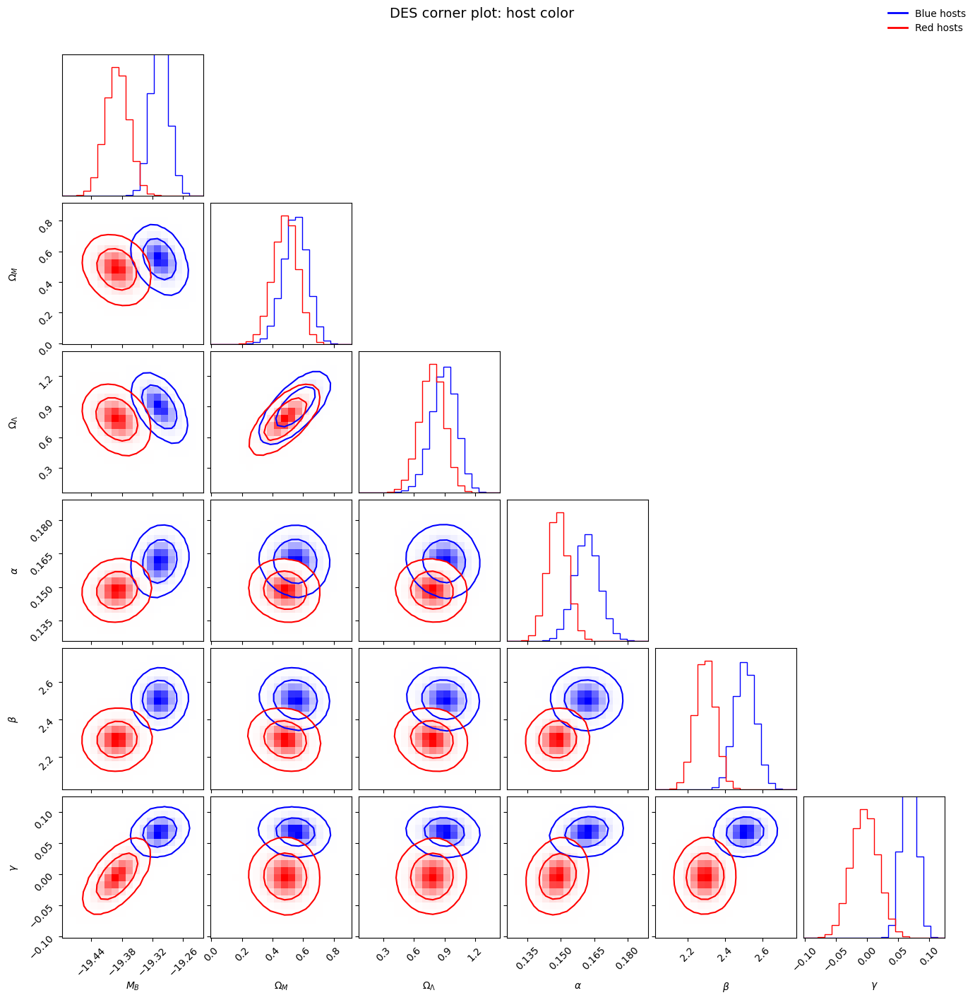

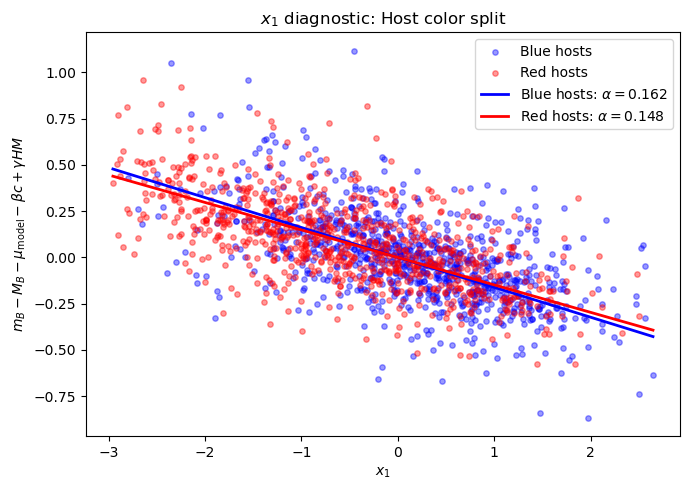

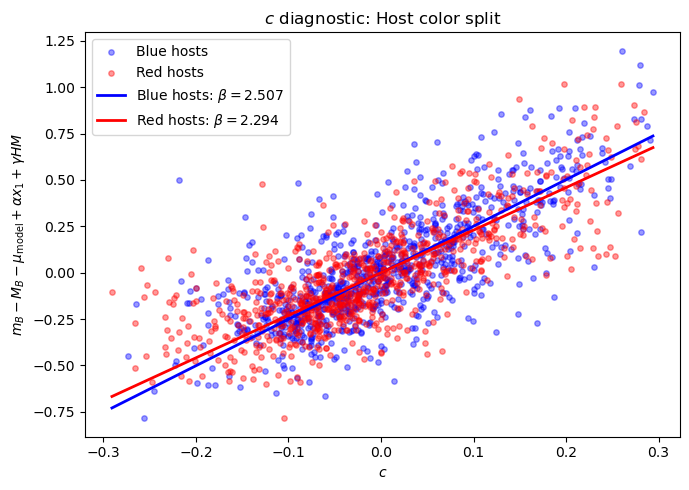

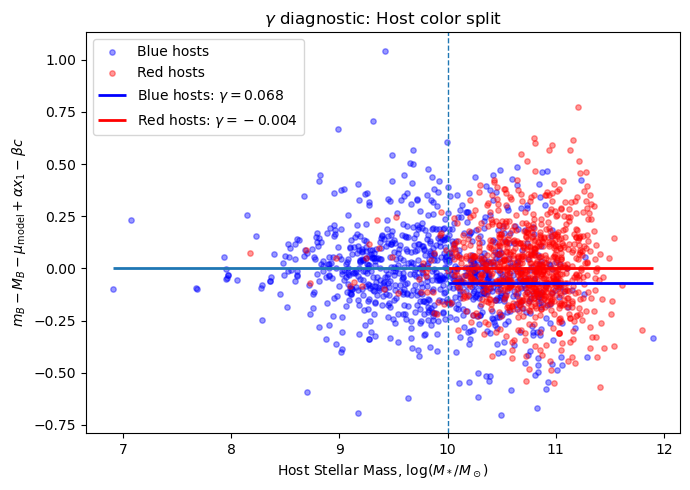

In [36]:
plot_overlaid_corner(
    clipped_blue_samples_6d,
    clipped_red_samples_6d,
    "Blue hosts",
    "Red hosts",
    "DES corner plot: host color",
    "blue",
    "red",
    filename=clipped_6d_dir / "DES_clipped_corner_host_color_6d.png"
)


plot_mcmc_diagnostics_split(
    clipped_blue_df_6d,
    clipped_blue_samples_6d,
    clipped_red_df_6d,
    clipped_red_samples_6d,
    low_label="Blue hosts",
    high_label="Red hosts",
    low_color="blue",
    high_color="red",
    title="Host color split",
    filename_prefix="DES_host_color",
    clipped=True
)

In [37]:
clipped_low_ssfr_sampler_6d, clipped_low_ssfr_samples_6d = run_mcmc(
    clipped_low_ssfr_data_6d,
    initial_guess_6d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=171
)

clipped_low_ssfr_summary_6d = summarize_samples(
    "Low-sSFR hosts: clipped 6-parameter LambdaCDM",
    clipped_low_ssfr_samples_6d,
    filename=clipped_6d_dir / "DES_low_ssfr_6d_clipped.txt"
)

clipped_high_ssfr_sampler_6d, clipped_high_ssfr_samples_6d = run_mcmc(
    clipped_high_ssfr_data_6d,
    initial_guess_6d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=172
)

clipped_high_ssfr_summary_6d = summarize_samples(
    "High-sSFR hosts: clipped 6-parameter LambdaCDM",
    clipped_high_ssfr_samples_6d,
    filename=clipped_6d_dir / "DES_high_ssfr_6d_clipped.txt"
)

np.save(clipped_6d_dir / "DES_clipped_low_ssfr_samples_6d.npy", clipped_low_ssfr_samples_6d)
np.save(clipped_6d_dir / "DES_clipped_high_ssfr_samples_6d.npy", clipped_high_ssfr_samples_6d)

100%|████████████████████████████████████| 4000/4000 [1:27:00<00:00,  1.31s/it]



Low-sSFR hosts: clipped 6-parameter LambdaCDM
M_B = -19.3746 -0.0216 +0.0219
Omega_M = 0.4921 -0.0948 +0.0908
Omega_Lambda = 0.7237 -0.1459 +0.1371
alpha = 0.1506 -0.0051 +0.0050
beta = 2.1151 -0.0641 +0.0661
gamma = 0.0103 -0.0235 +0.0236


100%|████████████████████████████████████| 4000/4000 [1:44:14<00:00,  1.56s/it]


High-sSFR hosts: clipped 6-parameter LambdaCDM
M_B = -19.3077 -0.0166 +0.0169
Omega_M = 0.4909 -0.0759 +0.0727
Omega_Lambda = 0.8293 -0.1197 +0.1143
alpha = 0.1574 -0.0050 +0.0051
beta = 2.5149 -0.0476 +0.0479
gamma = 0.0671 -0.0098 +0.0097


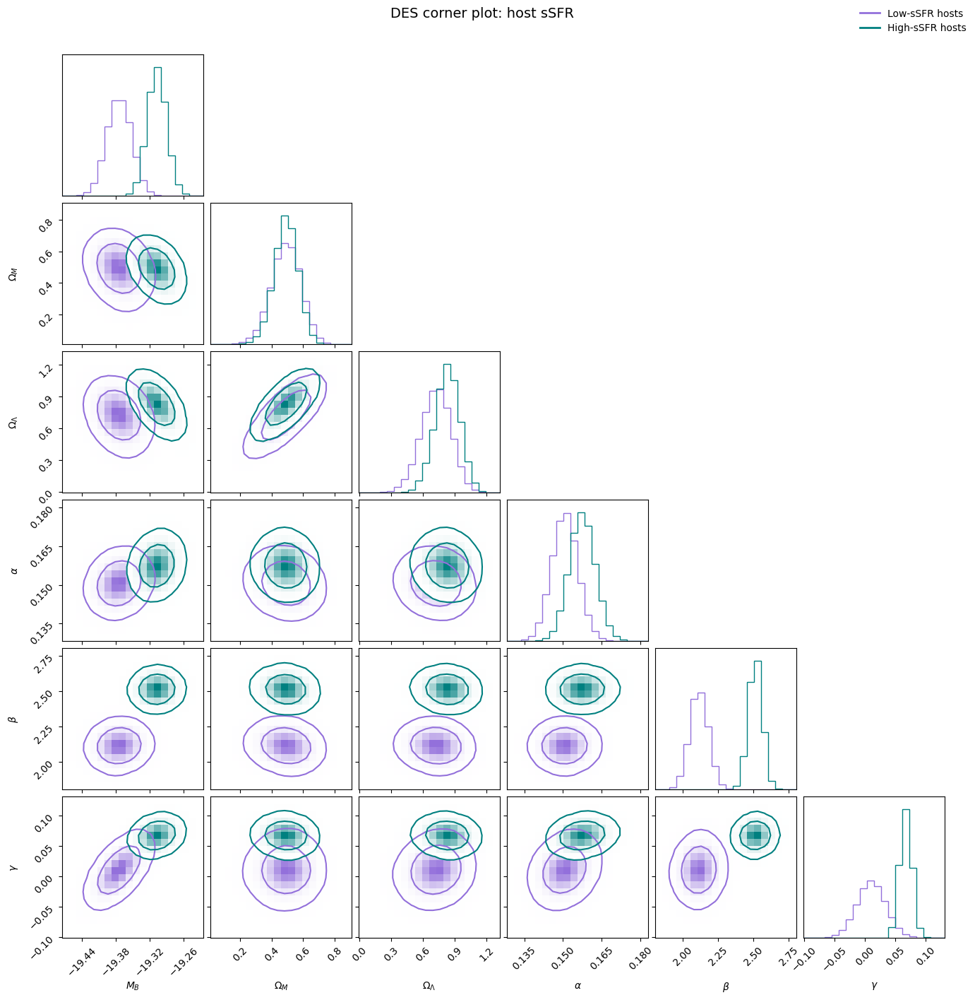

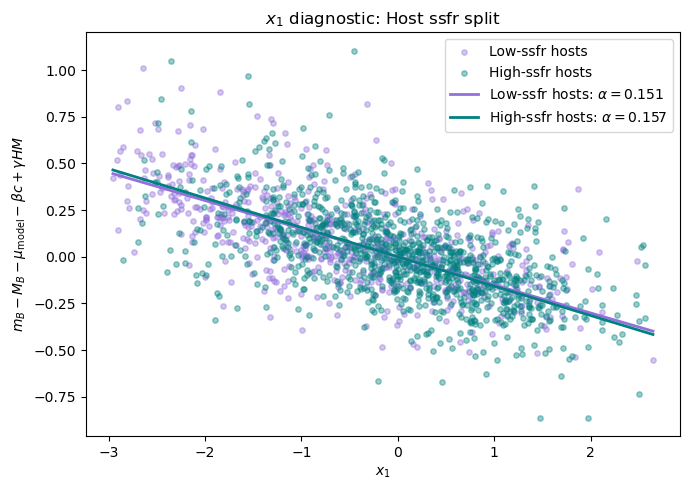

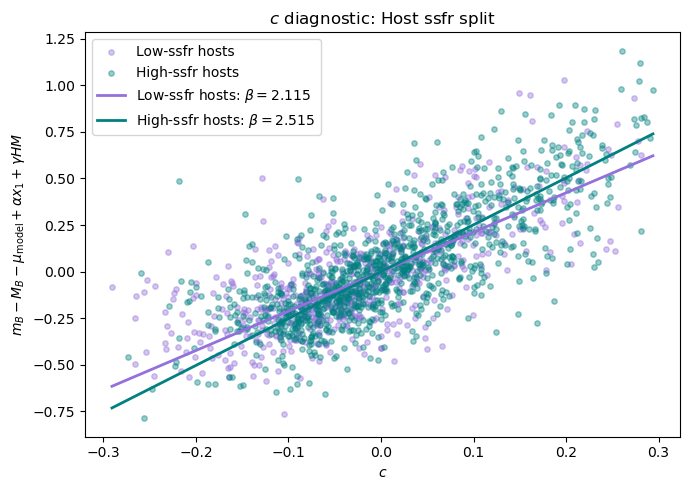

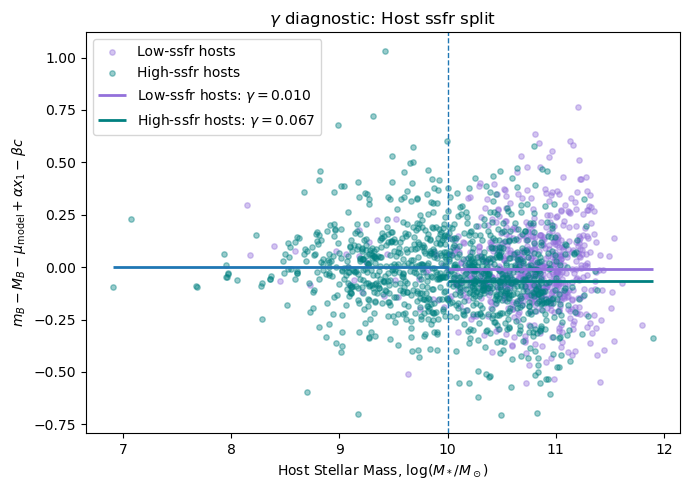

In [38]:
plot_overlaid_corner(
    clipped_low_ssfr_samples_6d,
    clipped_high_ssfr_samples_6d,
    "Low-sSFR hosts",
    "High-sSFR hosts",
    "DES corner plot: host sSFR",
    "mediumpurple",
    "teal",
    filename=clipped_6d_dir / "DES_clipped_corner_host_ssfr_6d.png"
)

plot_mcmc_diagnostics_split(
    clipped_low_ssfr_df_6d,
    clipped_low_ssfr_samples_6d,
    clipped_high_ssfr_df_6d,
    clipped_high_ssfr_samples_6d,
    low_label="Low-ssfr hosts",
    high_label="High-ssfr hosts",
    low_color="mediumpurple",
    high_color="teal",
    title="Host ssfr split",
    filename_prefix="DES_host_ssfr",
    clipped=True
)

In [19]:
clipped_all_sampler_6d, clipped_all_samples_6d = run_mcmc(
    clipped_all_data_6d,
    initial_guess_6d,
    nwalkers=nwalkers,
    nsteps=nsteps,
    burnin=burnin,
    thin=thin,
    random_seed=175
)

clipped_all_summary_6d = summarize_samples(
    "All DES supernovae: clipped 6-parameter LambdaCDM",
    clipped_all_samples_6d,
    filename=clipped_6d_dir / "DES_clipped_all_6d.txt"
)

np.save(clipped_6d_dir / "DES_clipped_all_samples_6d.npy", clipped_all_samples_6d)

100%|████████████████████████████████████| 4000/4000 [1:59:29<00:00,  1.79s/it]


All DES supernovae: clipped 6-parameter LambdaCDM
M_B = -19.3202 -0.0115 +0.0115
Omega_M = 0.5161 -0.0559 +0.0550
Omega_Lambda = 0.8753 -0.0835 +0.0816
alpha = 0.1529 -0.0036 +0.0037
beta = 2.4156 -0.0377 +0.0382
gamma = 0.0753 -0.0081 +0.0080


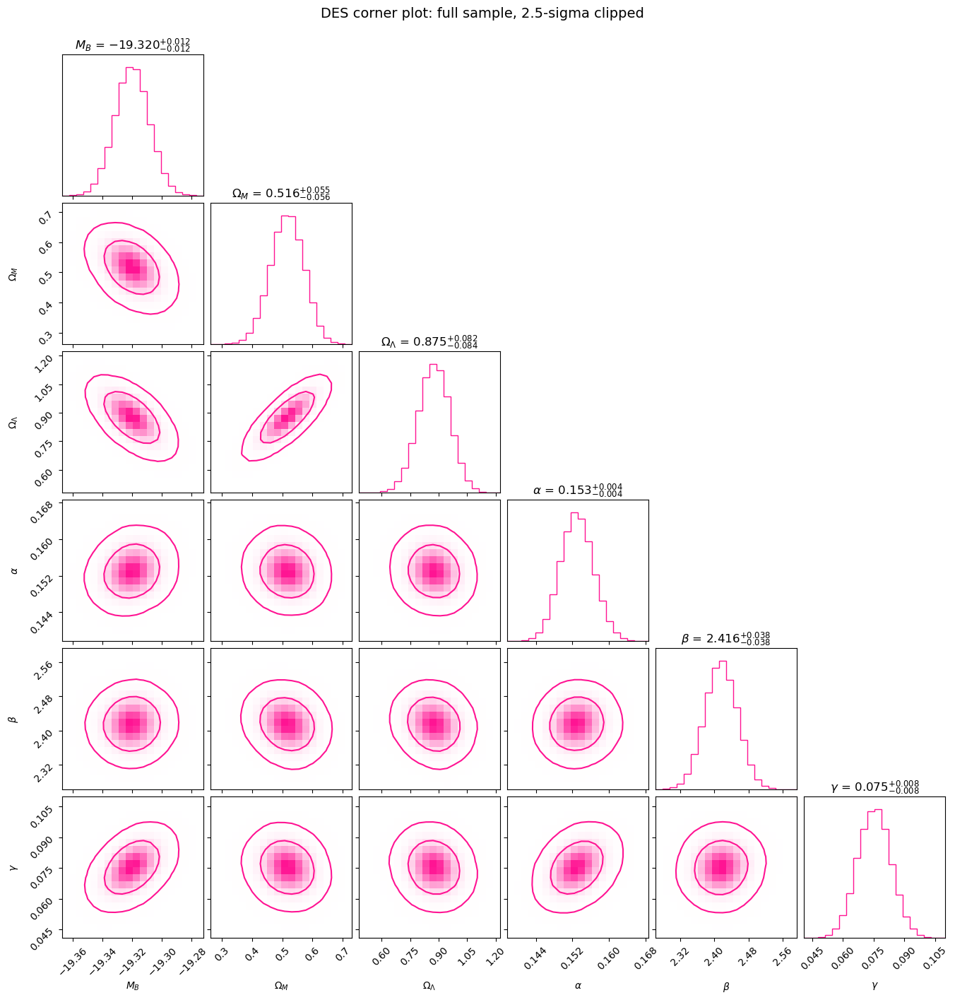

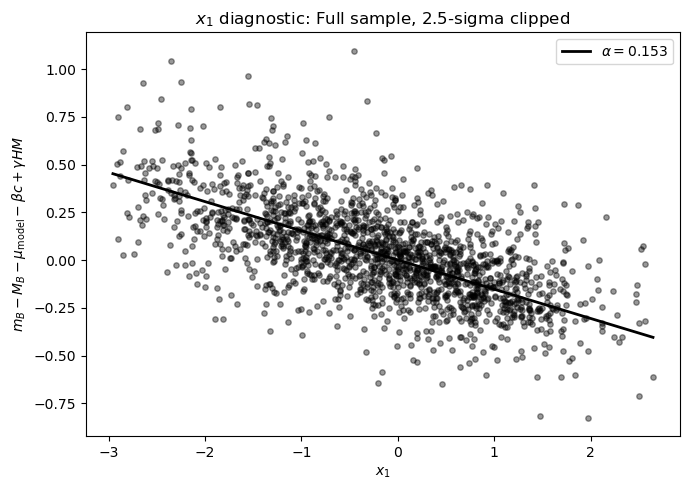

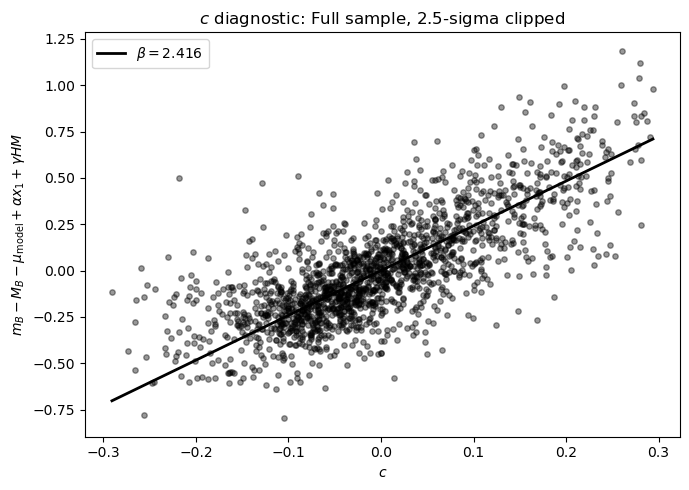

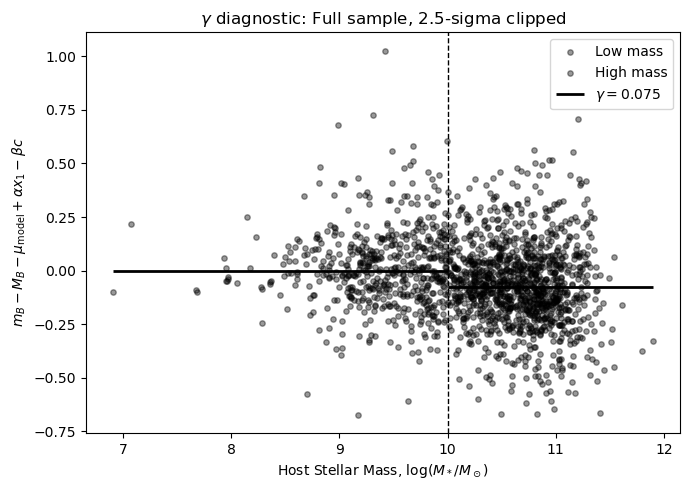

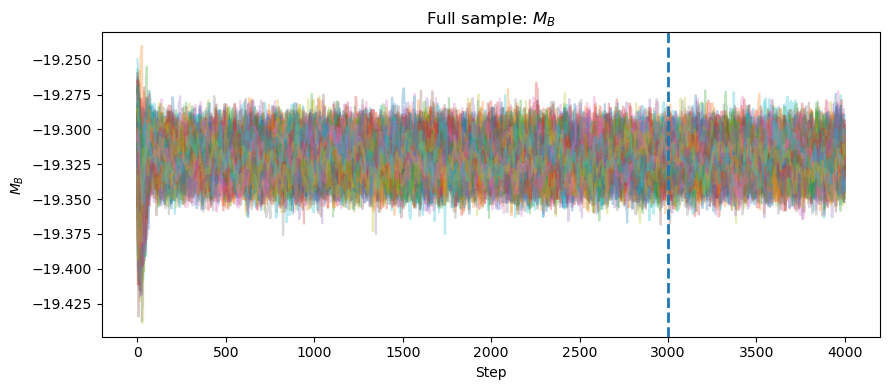

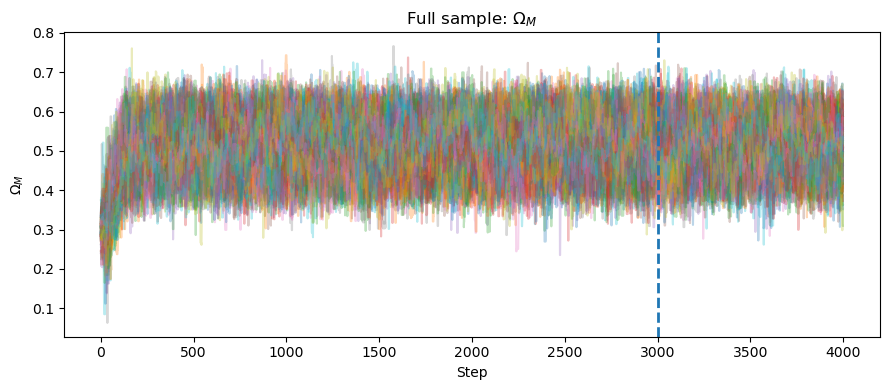

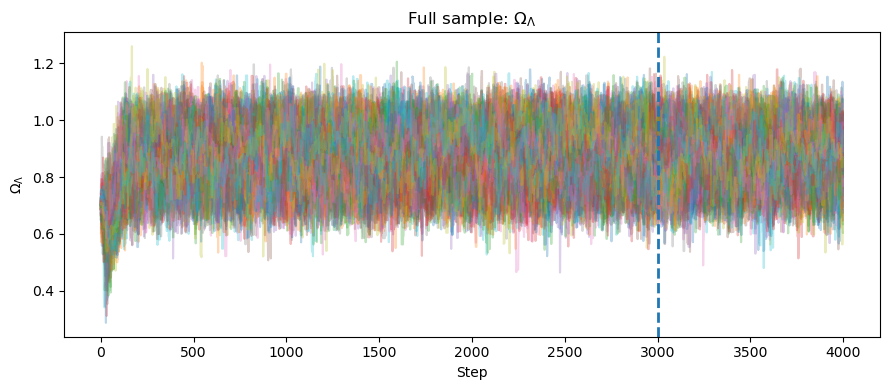

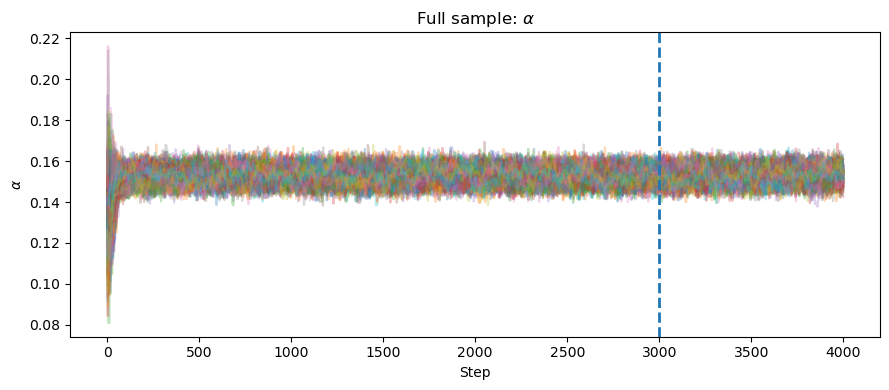

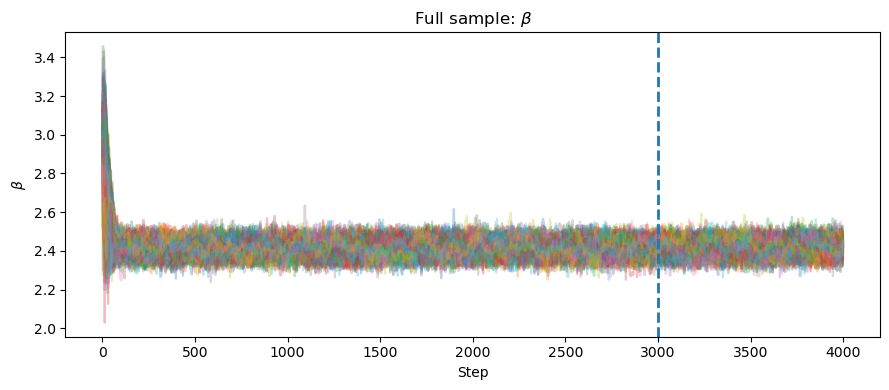

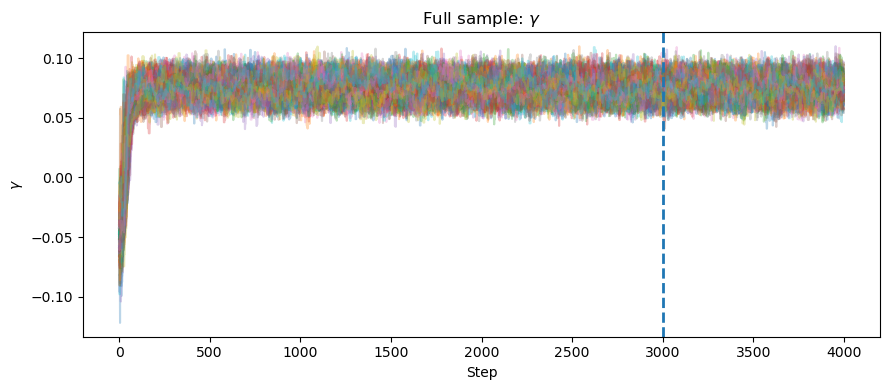

In [49]:
fig = corner.corner(
    clipped_all_samples_6d,
    labels=[
        r"$M_B$",
        r"$\Omega_M$",
        r"$\Omega_\Lambda$",
        r"$\alpha$",
        r"$\beta$",
        r"$\gamma$"
    ],
    levels=(0.683, 0.954),
    color="deeppink",
    plot_datapoints=False,
    plot_density=True,
    fill_contours=False,
    smooth=1.0,
    show_titles=True,
    title_fmt=".3f"
)

fig.suptitle("DES corner plot: full sample, 2.5-sigma clipped", fontsize=14, y=1.02)

fig.savefig(
    clipped_6d_dir / "DES_clipped_corner_full_sample_6d.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plot_mcmc_diagnostics(
    des_sample_clipped_6d,
    clipped_all_samples_6d,
    title="Full sample, 2.5-sigma clipped",
    filename_prefix="DES_full_sample",
    clipped=True
)

plot_burnin_diagnostics(
    clipped_all_sampler_6d,
    burnin=burnin,
    title="Full sample",
    filename_prefix="DES_full_sample",
    clipped=True
)

# Final Hubble Diagrams

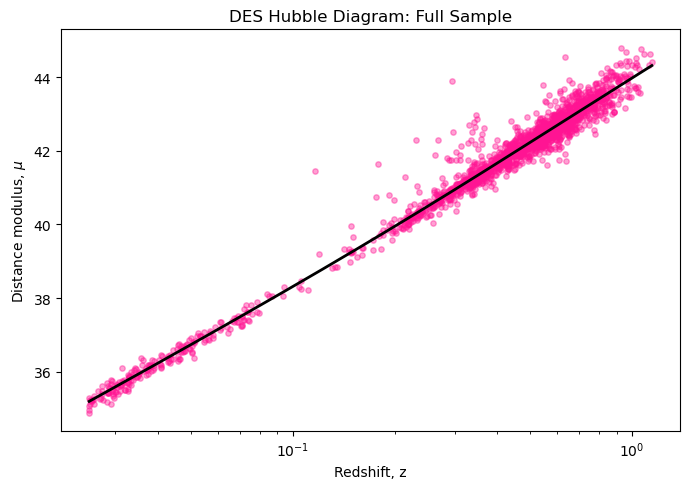

In [21]:
M_B = np.median(all_samples_6d[:, 0])
Omega_M = np.median(all_samples_6d[:, 1])
Omega_Lambda = np.median(all_samples_6d[:, 2])
alpha = np.median(all_samples_6d[:, 3])
beta = np.median(all_samples_6d[:, 4])
gamma = np.median(all_samples_6d[:, 5])

data = des_sample_6d[["zHD", "mB", "x1", "c", "HOST_LOGMASS"]].dropna().copy()

HM = (data["HOST_LOGMASS"] >= mass_cut).astype(float)

data["MU"] = data["mB"] - M_B + alpha*data["x1"] - beta*data["c"] + gamma*HM

cosmology = LambdaCDM(H0=H_0, Om0=Omega_M, Ode0=Omega_Lambda)

z_plot = np.linspace(data["zHD"].min(), data["zHD"].max(), 500)
mu_plot = cosmology.distmod(z_plot).value

plt.figure(figsize=(7, 5))

plt.scatter(
    data["zHD"],
    data["MU"],
    s=15,
    alpha=0.4,
    color="deeppink"
)

plt.plot(
    z_plot,
    mu_plot,
    color="black",
    linewidth=2
)

plt.xscale("log")
plt.xlabel("Redshift, z")
plt.ylabel(r"Distance modulus, $\mu$")
plt.title("DES Hubble Diagram: Full Sample")
plt.tight_layout()
plt.savefig(hubble_dir / "DES_hubble_full_sample.png", dpi=300, bbox_inches="tight")
plt.show()

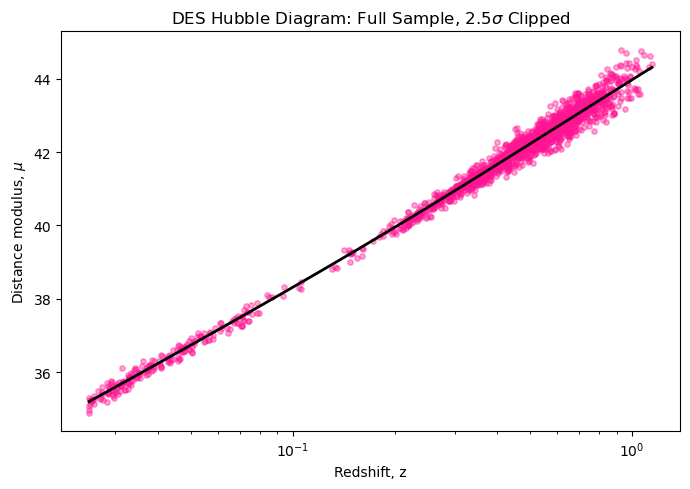

In [37]:
# 2.5-sigma clipped 6D Hubble diagram

M_B = np.median(clipped_all_samples_6d[:, 0])
Omega_M = np.median(clipped_all_samples_6d[:, 1])
Omega_Lambda = np.median(clipped_all_samples_6d[:, 2])
alpha = np.median(clipped_all_samples_6d[:, 3])
beta = np.median(clipped_all_samples_6d[:, 4])
gamma = np.median(clipped_all_samples_6d[:, 5])

data = des_sample_clipped_6d[
    ["zHD", "mB", "x1", "c", "HOST_LOGMASS"]
].dropna().copy()

HM = (data["HOST_LOGMASS"] >= mass_cut).astype(float)

data["MU"] = data["mB"] - M_B + alpha*data["x1"] - beta*data["c"] + gamma*HM

cosmology = LambdaCDM(
    H0=H_0,
    Om0=Omega_M,
    Ode0=Omega_Lambda
)

z_plot = np.linspace(
    data["zHD"].min(),
    data["zHD"].max(),
    500
)

mu_plot = cosmology.distmod(z_plot).value

plt.figure(figsize=(7, 5))

plt.scatter(
    data["zHD"],
    data["MU"],
    s=15,
    alpha=0.4,
    color="deeppink"
)

plt.plot(
    z_plot,
    mu_plot,
    color="black",
    linewidth=2
)

plt.xscale("log")
plt.xlabel("Redshift, z")
plt.ylabel(r"Distance modulus, $\mu$")
plt.title(r"DES Hubble Diagram: Full Sample, $2.5\sigma$ Clipped")

plt.tight_layout()

plt.savefig(
    hubble_dir / "DES_hubble_full_sample_6d_2p5sigma_clipped.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
def plot_hubble_split(
    sample1,
    sample2,
    samples1,
    samples2,
    label1,
    label2,
    color1,
    color2,
    title,
    filename
):
    M_B_1 = np.median(samples1[:, 0])
    Omega_M_1 = np.median(samples1[:, 1])
    Omega_Lambda_1 = np.median(samples1[:, 2])
    alpha_1 = np.median(samples1[:, 3])
    beta_1 = np.median(samples1[:, 4])
    gamma_1 = np.median(samples1[:, 5]) if samples1.shape[1] > 5 else 0.0

    M_B_2 = np.median(samples2[:, 0])
    Omega_M_2 = np.median(samples2[:, 1])
    Omega_Lambda_2 = np.median(samples2[:, 2])
    alpha_2 = np.median(samples2[:, 3])
    beta_2 = np.median(samples2[:, 4])
    gamma_2 = np.median(samples2[:, 5]) if samples2.shape[1] > 5 else 0.0

    data1 = sample1[["zHD", "mB", "x1", "c", "HOST_LOGMASS"]].dropna().copy()
    data2 = sample2[["zHD", "mB", "x1", "c", "HOST_LOGMASS"]].dropna().copy()

    HM1 = (data1["HOST_LOGMASS"] >= mass_cut).astype(float)
    HM2 = (data2["HOST_LOGMASS"] >= mass_cut).astype(float)

    data1["MU"] = data1["mB"] - M_B_1 + alpha_1*data1["x1"] - beta_1*data1["c"] + gamma_1*HM1
    data2["MU"] = data2["mB"] - M_B_2 + alpha_2*data2["x1"] - beta_2*data2["c"] + gamma_2*HM2

    cosmology1 = LambdaCDM(H0=H_0, Om0=Omega_M_1, Ode0=Omega_Lambda_1)
    cosmology2 = LambdaCDM(H0=H_0, Om0=Omega_M_2, Ode0=Omega_Lambda_2)

    z_min = min(data1["zHD"].min(), data2["zHD"].min())
    z_max = max(data1["zHD"].max(), data2["zHD"].max())
    z_plot = np.linspace(z_min, z_max, 500)

    plt.figure(figsize=(7, 5))

    plt.scatter(data1["zHD"], data1["MU"], s=15, alpha=0.4, color=color1, label=label1)
    plt.scatter(data2["zHD"], data2["MU"], s=15, alpha=0.4, color=color2, label=label2)

    plt.plot(z_plot, cosmology1.distmod(z_plot).value, color=color1, linewidth=2)
    plt.plot(z_plot, cosmology2.distmod(z_plot).value, color=color2, linewidth=2)

    plt.xscale("log")
    plt.xlabel("Redshift, z")
    plt.ylabel(r"Distance modulus, $\mu$")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

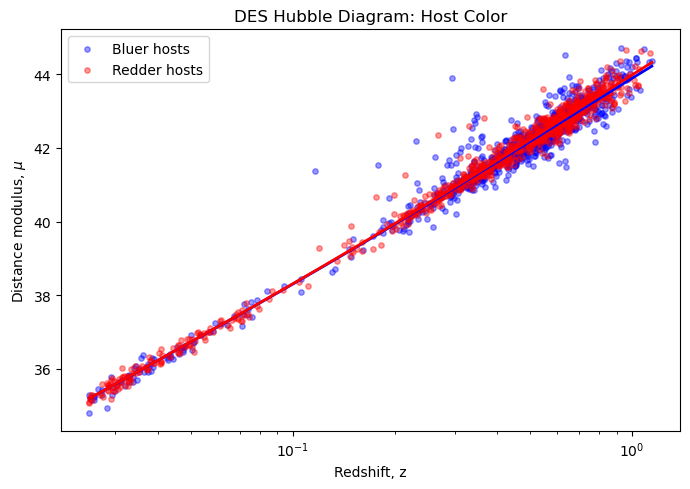

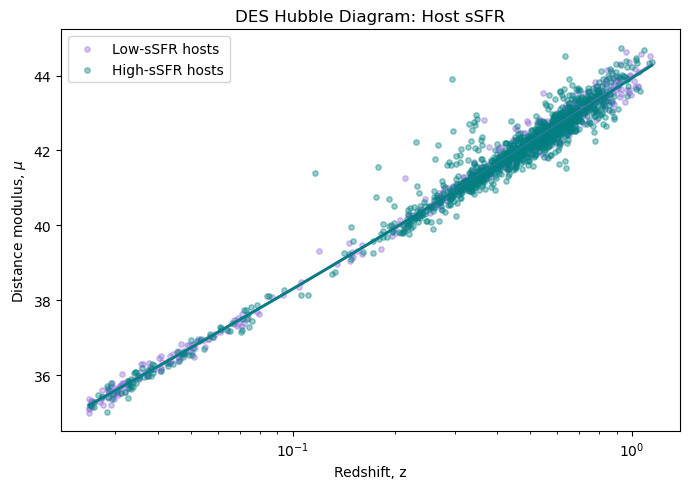

In [31]:
plot_hubble_split(
    blue_df_6d,
    red_df_6d,
    blue_samples_6d,
    red_samples_6d,
    "Bluer hosts",
    "Redder hosts",
    "blue",
    "red",
    "DES Hubble Diagram: Host Color",
    hubble_dir / "DES_hubble_host_color.png"
)

plot_hubble_split(
    low_ssfr_df_6d,
    high_ssfr_df_6d,
    low_ssfr_samples_6d,
    high_ssfr_samples_6d,
    "Low-sSFR hosts",
    "High-sSFR hosts",
    "mediumpurple",
    "teal",
    "DES Hubble Diagram: Host sSFR",
    hubble_dir / "DES_hubble_host_ssfr.png"
)

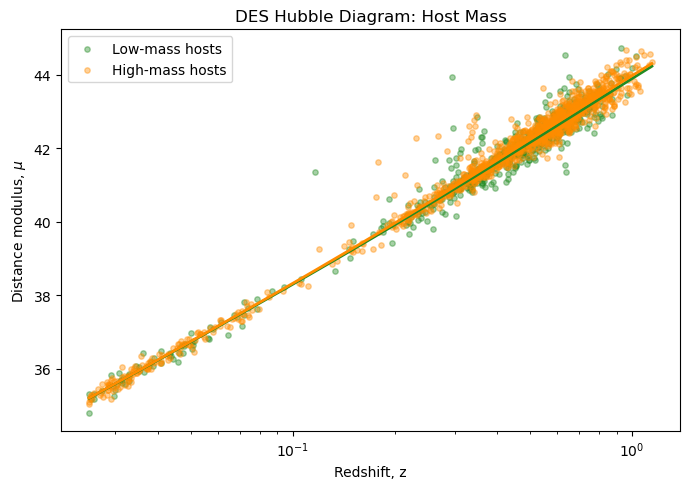

In [32]:
plot_hubble_split(
    low_mass_df_5d,
    high_mass_df_5d,
    low_mass_samples_5d,
    high_mass_samples_5d,
    "Low-mass hosts",
    "High-mass hosts",
    "forestgreen",
    "darkorange",
    "DES Hubble Diagram: Host Mass",
    hubble_dir / "DES_hubble_host_mass.png"
)

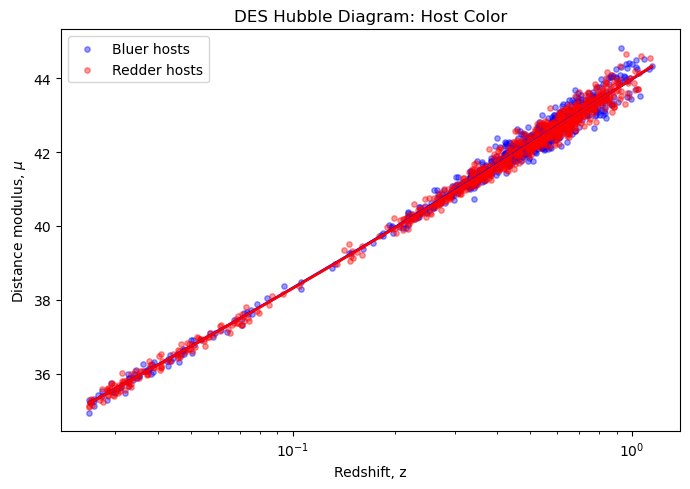

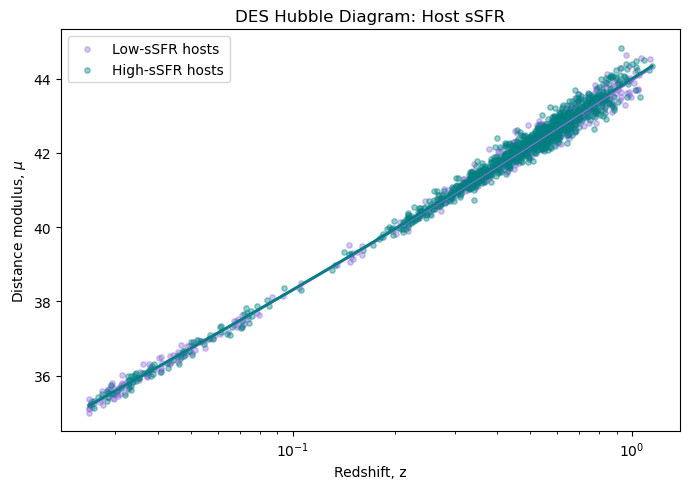

In [33]:
plot_hubble_split(
    clipped_blue_df_6d,
    clipped_red_df_6d,
    clipped_blue_samples_6d,
    clipped_red_samples_6d,
    "Bluer hosts",
    "Redder hosts",
    "blue",
    "red",
    "DES Hubble Diagram: Host Color",
    hubble_dir / "DES_clipped_hubble_host_color.png"
)

plot_hubble_split(
    clipped_low_ssfr_df_6d,
    clipped_high_ssfr_df_6d,
    clipped_low_ssfr_samples_6d,
    clipped_high_ssfr_samples_6d,
    "Low-sSFR hosts",
    "High-sSFR hosts",
    "mediumpurple",
    "teal",
    "DES Hubble Diagram: Host sSFR",
    hubble_dir / "DES_clipped_hubble_host_ssfr.png"
)

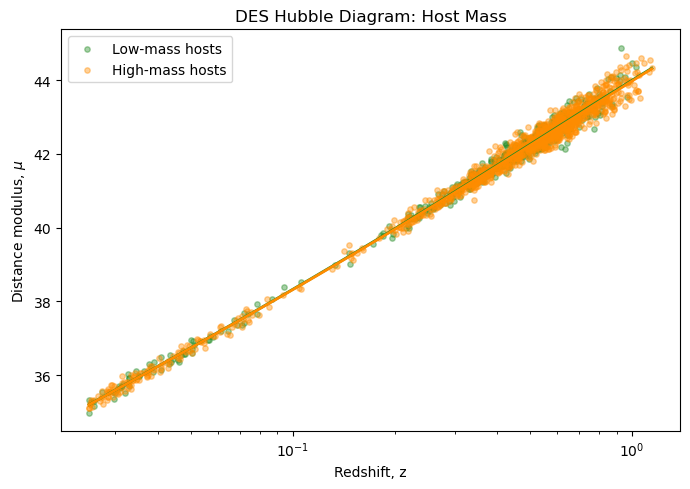

In [34]:
plot_hubble_split(
    clipped_low_mass_df_5d,
    clipped_high_mass_df_5d,
    clipped_low_mass_samples_5d,
    clipped_high_mass_samples_5d,
    "Low-mass hosts",
    "High-mass hosts",
    "forestgreen",
    "darkorange",
    "DES Hubble Diagram: Host Mass",
    hubble_dir / "DES_clipped_hubble_host_mass.png"
)

In [35]:
# is the right thing to do always to split it up? 
# do we get same splits between datasets. can we connect redshifts
# when we split on galaxies we split on mass so maybe we don't need mass step anymore (5D vs 6D)?

# start writing up narrative of what i've done
# google slide deck or google doc to keep track of plots and stuff every week, need to think about organization